# WasteWise AI — Colab Training Notebook

**Goal:** fine-tune a small pretrained Ultralytics YOLO model to detect four kinds of waste in an image and report a box, class name and confidence for each object.

**Supported classes (to be verified against the dataset in Section 6):** Plastic Bottle, Plastic Bag, Plastic Waste, Paper.

**Dataset:** Bangladesh Recyclable Waste Object Detection Dataset — https://zenodo.org/records/22043339

### Before you start
1. Choose a GPU: **Runtime → Change runtime type → T4 GPU** (or any GPU). Free GPU access is *not guaranteed* and sessions can end at any time.
2. Colab's `/content` storage is **temporary**. Everything that matters (archive, YAML, weights, reports) is saved to Google Drive.
3. Run the cells **top to bottom**. Read the short note above each cell first.
4. WasteWise AI is an *advisory* detector. It does not sort waste and a prediction does not prove an item is recyclable under local rules.

### Workflow

| Section | What happens |
|---|---|
| 1 | Check Python, GPU and package versions |
| 2 | Mount Drive and set all settings in one config cell |
| 3 | Download the dataset (or use a file you placed in Drive) |
| 4 | Inspect the archive and extract it safely |
| 5 | Discover the real image / label / split layout |
| 6 | Verify class names, audit every image and label |
| 7 | Build `data.yaml` |
| 8 | Draw ground-truth boxes (visual gate) |
| 9 | Train |
| 10 | Inspect training results |
| 11 | Evaluate on the held-out test set |
| 12 | Predict on your own image |
| 13 | Export the model and metadata to Drive |
| 14 | Final summary and troubleshooting |

> Nothing in this notebook contains pre-written results. Every number and picture comes from the code you run.

## Section 1 — Environment and GPU check

**What it does:** prints the Python version, tells you whether a GPU is active, and installs `ultralytics` only if it is missing. Colab already ships a working PyTorch, so we do **not** reinstall or downgrade it.

**Expected output:** versions and either a GPU name or a clear CPU warning.

**If it fails:** if PyTorch is missing (non-Colab machine), install it first from pytorch.org.

In [2]:
import sys
import platform
import subprocess
import importlib.util
from importlib import metadata

print("Python:", sys.version.split()[0], "|", platform.platform())

try:
    import torch
except ImportError as err:
    raise RuntimeError("PyTorch is not installed. On Colab it normally is; elsewhere install it from pytorch.org.") from err

HAS_GPU = torch.cuda.is_available()
if HAS_GPU:
    gpu = torch.cuda.get_device_properties(0)
    print(f"GPU active: {gpu.name} ({gpu.total_memory / 1e9:.1f} GB memory)")
else:
    print("WARNING: no GPU detected. Training on CPU works but is very slow.")
    print("         Use Runtime -> Change runtime type -> GPU, or lower EPOCHS / IMAGE_SIZE in Section 2.")

# Install ultralytics only when it is not already available (do not touch torch).
if importlib.util.find_spec("ultralytics") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


def package_version(*names):
    """Return the version of the first installed package from `names`."""
    for name in names:
        try:
            return metadata.version(name)
        except metadata.PackageNotFoundError:
            continue
    return "not installed"


PACKAGE_VERSIONS = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "torchvision": package_version("torchvision"),
    "ultralytics": package_version("ultralytics"),
    "opencv": package_version("opencv-python", "opencv-python-headless"),
    "numpy": package_version("numpy"),
    "pandas": package_version("pandas"),
    "matplotlib": package_version("matplotlib"),
    "pillow": package_version("pillow"),
    "pyyaml": package_version("pyyaml"),
}
for package, version in PACKAGE_VERSIONS.items():
    print(f"{package:12s} {version}")

Python: 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39
GPU active: Tesla T4 (15.6 GB memory)
python       3.13.15
torch        2.11.0+cu130
torchvision  0.26.0+cu130
ultralytics  8.4.183
opencv       5.0.0.93
numpy        2.1.3
pandas       2.2.3
matplotlib   3.10.0
pillow       11.3.0
pyyaml       6.0.3


## Section 2 — Mount Google Drive and configure everything

**What it does:** mounts Drive (in Colab) and defines **all settings in one place**. Change values here, nothing else.

**Notes**
- `DATASET_DIR` defaults to `/content/...` (fast local disk) because reading thousands of small files from Drive is slow. The archive itself stays in Drive, so re-extracting after a runtime reset is cheap.
- `BATCH_SIZE`: if you see an *out of memory* error later, lower it (16 → 8 → 4).
- `CLASS_NAMES_CONFIRMED` is a safety switch used in Section 6 if the dataset does not ship its own class list.

**If it fails:** if Drive does not mount, re-run the cell and approve the pop-up.

In [4]:
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not running in Colab - using local folders instead of Google Drive.")

# ------------------------------------------------------------------
# SETTINGS (edit here)
# ------------------------------------------------------------------
if IN_COLAB:
    PROJECT_DIR = Path("/content/drive/MyDrive/WasteWise_AI")      # persistent storage
    DATASET_DIR = Path("/content/wastewise_dataset")               # extracted data (temporary, fast)
    PREPARED_DIR = Path("/content/wastewise_yolo_ready")           # only used if the layout needs fixing
else:
    PROJECT_DIR = Path("WasteWise_AI").resolve()
    DATASET_DIR = PROJECT_DIR / "dataset_extracted"
    PREPARED_DIR = PROJECT_DIR / "dataset_prepared"

ZENODO_RECORD_ID = "22043339"
ZENODO_FILE_NAME = None          # set only if the record contains several archives

ARCHIVE_DIR = PROJECT_DIR / "downloads"                 # put a manually downloaded archive here
CONFIG_DIR = PROJECT_DIR / "configs"
OUTPUT_DIR = PROJECT_DIR / "training_outputs"
REPORTS_DIR = PROJECT_DIR / "reports"
FINAL_MODEL_DIR = PROJECT_DIR / "final_model"
PREDICTIONS_DIR = PROJECT_DIR / "predictions"

RUN_NAME = "wastewise_yolo"
MODEL_NAME = "yolo11n.pt"        # small pretrained detector (needs a recent ultralytics)
IMAGE_SIZE = 640
EPOCHS = 50
BATCH_SIZE = 16                  # reduce if the GPU runs out of memory
PATIENCE = 10                    # stop early if validation does not improve for this many epochs
CONFIDENCE_THRESHOLD = 0.25      # used for predictions and error analysis
IOU_THRESHOLD = 0.7              # NMS overlap threshold for predictions
RANDOM_SEED = 42
FORCE_RETRAIN = False            # True = train again even if a finished run already exists

# Expected classes, used ONLY if the dataset has no class list of its own.
EXPECTED_CLASS_NAMES = ["Plastic Bottle", "Plastic Bag", "Plastic Waste", "Paper"]
CLASS_NAMES_CONFIRMED = False    # set True only after you checked the boxes in Section 8

# Only used when the dataset has no usable train/val split (see Section 5).
ALLOW_FALLBACK_SPLIT = True

for folder in [ARCHIVE_DIR, CONFIG_DIR, OUTPUT_DIR, REPORTS_DIR, FINAL_MODEL_DIR, PREDICTIONS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/WasteWise_AI


## Section 3 — Download (or locate) the dataset

**What it does**
1. If you already placed a `.zip` / `.tar*` archive in `ARCHIVE_DIR`, it is used and nothing is downloaded.
2. Otherwise the notebook asks the official Zenodo API for the file list of the record, picks the archive, downloads it into Drive and checks size / MD5 when Zenodo provides them.
3. The record's title, license and DOI are printed and saved. **Read the license before sharing or commercial use.**

**Expected output:** the archive path and its size.

**If it fails:** download the archive manually from https://zenodo.org/records/22043339 and upload it to the `downloads` folder inside `WasteWise_AI` on your Drive, then re-run this cell.

In [5]:
import re
import json
import hashlib
import requests

ARCHIVE_EXTS = (".zip", ".tar", ".tar.gz", ".tgz", ".tar.bz2", ".tar.xz")


def fetch_zenodo_record():
    """Ask the Zenodo API about the record. Returns None if it cannot be reached."""
    try:
        response = requests.get(f"https://zenodo.org/api/records/{ZENODO_RECORD_ID}", timeout=30)
        response.raise_for_status()
        return response.json()
    except Exception as err:
        print("Could not read the Zenodo record automatically:", err)
        return None


def list_record_files(record):
    """Return [{'name', 'size', 'checksum', 'url'}] for every file in the record."""
    files = record.get("files", [])
    if isinstance(files, dict):                       # newer API layout
        files = list(files.get("entries", {}).values())
    result = []
    for item in files:
        name = item.get("key") or item.get("filename")
        links = item.get("links", {})
        url = links.get("self") or links.get("download") or links.get("content")
        if url is None and name:                       # standard Zenodo pattern, built from the real file name
            url = f"https://zenodo.org/records/{ZENODO_RECORD_ID}/files/{name}?download=1"
        result.append({"name": name, "size": item.get("size"), "checksum": item.get("checksum"), "url": url})
    return result


def md5_of_file(path):
    digest = hashlib.md5()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def download_file(url, destination, expected_size=None, expected_md5=None):
    """Stream a download to a .part file, verify it, then rename it."""
    temp_path = destination.with_name(destination.name + ".part")
    with requests.get(url, stream=True, timeout=60) as response:
        response.raise_for_status()
        total = int(response.headers.get("content-length", 0)) or expected_size or 0
        done, next_report = 0, 50 * 1024 * 1024
        with open(temp_path, "wb") as handle:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                handle.write(chunk)
                done += len(chunk)
                if done >= next_report:
                    print(f"  downloaded {done / 1e6:.0f} MB" + (f" of {total / 1e6:.0f} MB" if total else ""))
                    next_report += 50 * 1024 * 1024
    if expected_size and temp_path.stat().st_size != expected_size:
        raise RuntimeError(f"Size mismatch: got {temp_path.stat().st_size}, expected {expected_size}. Delete and retry.")
    if expected_md5 and md5_of_file(temp_path) != expected_md5:
        raise RuntimeError("MD5 checksum mismatch - the download is corrupt. Delete it and retry.")
    temp_path.rename(destination)


def show_record_info(record):
    meta = record.get("metadata", {})
    license_info = meta.get("license")
    license_text = license_info.get("id") if isinstance(license_info, dict) else license_info
    print("Title  :", meta.get("title"))
    print("DOI    :", record.get("doi") or meta.get("doi"))
    print("License:", license_text or "not listed - check the Zenodo page")
    creators = [c.get("name") for c in meta.get("creators", []) if isinstance(c, dict)]
    print("Authors:", "; ".join(filter(None, creators)) or "see Zenodo page")
    description = re.sub(r"<[^>]+>", " ", meta.get("description", ""))
    print("About  :", " ".join(description.split())[:600])
    summary = {
        "record_url": f"https://zenodo.org/records/{ZENODO_RECORD_ID}",
        "title": meta.get("title"),
        "doi": record.get("doi") or meta.get("doi"),
        "license": license_text,
        "creators": creators,
    }
    (CONFIG_DIR / "zenodo_record.json").write_text(json.dumps(summary, indent=2))


record = fetch_zenodo_record()
if record:
    show_record_info(record)

local_archives = sorted(p for p in ARCHIVE_DIR.glob("*") if p.name.lower().endswith(ARCHIVE_EXTS))
if local_archives:
    ARCHIVE_PATH = local_archives[0]
    if len(local_archives) > 1:
        print("Several archives found, using the first one:", [p.name for p in local_archives])
    print("Using existing archive:", ARCHIVE_PATH.name)
else:
    if record is None:
        raise RuntimeError(
            "No archive found and the Zenodo record could not be read.\n"
            f"Download it manually from https://zenodo.org/records/{ZENODO_RECORD_ID} and place it in:\n  {ARCHIVE_DIR}"
        )
    files = list_record_files(record)
    print("\nFiles in the record:")
    for item in files:
        print(f"  {item['name']}  ({(item['size'] or 0) / 1e6:.0f} MB)")
    archives = [f for f in files if f["name"] and f["name"].lower().endswith(ARCHIVE_EXTS)]
    if ZENODO_FILE_NAME:
        archives = [f for f in files if f["name"] == ZENODO_FILE_NAME]
    if len(archives) != 1:
        raise RuntimeError(
            f"Expected exactly one archive but found {len(archives)}. Set ZENODO_FILE_NAME in Section 2 "
            f"or download manually and place the file in {ARCHIVE_DIR}."
        )
    chosen = archives[0]
    checksum = chosen["checksum"] or ""
    expected_md5 = checksum.split(":", 1)[1] if checksum.startswith("md5:") else None
    ARCHIVE_PATH = ARCHIVE_DIR / chosen["name"]
    print(f"\nDownloading {chosen['name']} ...")
    download_file(chosen["url"], ARCHIVE_PATH, chosen["size"], expected_md5)

print(f"\nArchive: {ARCHIVE_PATH}  ({ARCHIVE_PATH.stat().st_size / 1e6:.0f} MB)")

Title  : A Curated Recyclable Waste Object Detection Dataset from Public Spaces in Southeastern Bangladesh
DOI    : 10.5281/zenodo.22043339
License: cc-by-4.0
Authors: Mazumder, Shazzad Hossain
About  : This dataset comprises 2,842 high-resolution images (6,076 annotated object instances) collected across outdoor public spaces in southeastern Bangladesh. Annotations cover four primary recyclable solid waste categories: Plastic Bottle, Plastic Bag, Plastic Waste, and Paper. Partitions are provided for both canonical (75:15:10) and robustness (70:15:15) evaluations without offline data leakage.

Files in the record:
  bangladesh_recyclable_waste_dataset.zip  (438 MB)
  bangladesh_recyclable_waste_dataset.zip.sha256  (0 MB)

  downloaded 52 MB of 438 MB
  downloaded 105 MB of 438 MB
  downloaded 157 MB of 438 MB
  downloaded 210 MB of 438 MB
  downloaded 262 MB of 438 MB
  downloaded 315 MB of 438 MB
  downloaded 367 MB of 438 MB
  downloaded 419 MB of 438 MB

Archive: /content/drive/MyDr

## Section 4 — Inspect and extract the archive safely

**What it does:** lists what is inside *before* extracting, refuses archives with unsafe paths (for example `../../something`) or links, checks free disk space, extracts once, and prints the folder tree.

**Expected output:** member count, then a folder tree to depth 3.

**If it fails:** "unsafe member" means the archive is not trustworthy — do not extract it. "Not enough disk space" means restart the runtime or use a bigger one.

In [6]:
import os
import shutil
import zipfile
import tarfile

EXTRACT_MARKER = DATASET_DIR / ".extract_ok"


def inspect_archive(archive_path):
    """Return (list of (name, size, is_link_or_special)) for every member."""
    members = []
    if zipfile.is_zipfile(archive_path):
        with zipfile.ZipFile(archive_path) as zf:
            for info in zf.infolist():
                is_link = ((info.external_attr >> 16) & 0o170000) == 0o120000
                members.append((info.filename, info.file_size, is_link))
    elif tarfile.is_tarfile(archive_path):
        with tarfile.open(archive_path) as tf:
            for info in tf.getmembers():
                special = info.issym() or info.islnk() or info.isdev()
                members.append((info.name, info.size, special))
    else:
        raise RuntimeError(f"{archive_path.name} is not a readable zip/tar archive.")
    return members


def check_members_are_safe(members, target_dir):
    target = target_dir.resolve()
    for name, _, special in members:
        destination = (target / name).resolve()
        if not destination.is_relative_to(target):
            raise RuntimeError(f"Unsafe path in archive: {name}")
        if special:
            raise RuntimeError(f"Archive contains a link or special file: {name}")


def extract_archive(archive_path, target_dir):
    target_dir.mkdir(parents=True, exist_ok=True)
    if zipfile.is_zipfile(archive_path):
        with zipfile.ZipFile(archive_path) as zf:
            zf.extractall(target_dir)
    else:
        with tarfile.open(archive_path) as tf:
            try:
                tf.extractall(target_dir, filter="data")   # Python 3.12+ safety filter
            except TypeError:
                tf.extractall(target_dir)                  # older Python: we already checked every member


def print_tree(root, max_depth=3, max_entries=8):
    """Print a short folder tree (limited so the output stays readable)."""
    def walk(folder, depth):
        entries = sorted(folder.iterdir(), key=lambda p: (p.is_file(), p.name.lower()))
        folders = [e for e in entries if e.is_dir()]
        files = [e for e in entries if e.is_file()]
        for sub in folders[:max_entries]:
            n_files = sum(1 for _ in sub.rglob("*") if _.is_file())
            print("  " * depth + f"{sub.name}/  ({n_files} files)")
            if depth < max_depth:
                walk(sub, depth + 1)
        if len(folders) > max_entries:
            print("  " * depth + f"... {len(folders) - max_entries} more folders")
        for f in files[:max_entries]:
            print("  " * depth + f.name)
        if len(files) > max_entries:
            print("  " * depth + f"... {len(files) - max_entries} more files")
    print(root.name + "/")
    walk(root, 1)


archive_members = inspect_archive(ARCHIVE_PATH)
total_bytes = sum(size for _, size, _ in archive_members)
print(f"Archive has {len(archive_members)} entries, about {total_bytes / 1e6:.0f} MB uncompressed. First entries:")
for name, size, _ in archive_members[:10]:
    print("  ", name)

check_members_are_safe(archive_members, DATASET_DIR)
archive_stamp = f"{ARCHIVE_PATH.name}:{ARCHIVE_PATH.stat().st_size}"

if EXTRACT_MARKER.exists() and EXTRACT_MARKER.read_text() == archive_stamp:
    print("\nAlready extracted - skipping.")
else:
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    free_bytes = shutil.disk_usage(DATASET_DIR).free
    if free_bytes < total_bytes * 1.1:
        raise RuntimeError(f"Not enough disk space: need ~{total_bytes / 1e6:.0f} MB, have {free_bytes / 1e6:.0f} MB.")
    print("\nExtracting ...")
    extract_archive(ARCHIVE_PATH, DATASET_DIR)
    EXTRACT_MARKER.write_text(archive_stamp)
    print("Done.")

print("\nFolder tree:")
print_tree(DATASET_DIR)

Archive has 11383 entries, about 462 MB uncompressed. First entries:
   bangladesh_recyclable_waste_dataset/LICENSE
   bangladesh_recyclable_waste_dataset/README.md
   bangladesh_recyclable_waste_dataset/data_robustness_70-15-15/data.yaml
   bangladesh_recyclable_waste_dataset/data_robustness_70-15-15/README.roboflow.txt
   bangladesh_recyclable_waste_dataset/data_robustness_70-15-15/README.dataset.txt
   bangladesh_recyclable_waste_dataset/data_robustness_70-15-15/train/images/IMG-20250321-WA0120-copy_jpg.rf.9b04b9bacb175e1ed5a32da4ed82761f.jpg
   bangladesh_recyclable_waste_dataset/data_robustness_70-15-15/train/images/IMG-20250403-WA0317_jpg.rf.7f6305900e6db5e9c6e40147dec51c2b.jpg
   bangladesh_recyclable_waste_dataset/data_robustness_70-15-15/train/images/IMG_5018_JPG.rf.bc9aac9f6711af99d9589718dbb990ff.jpg
   bangladesh_recyclable_waste_dataset/data_robustness_70-15-15/train/images/IMG_4960_JPG.rf.1fefefaaaf434b064095404c44401f98.jpg
   bangladesh_recyclable_waste_dataset/data_rob

## Section 5 — Discover the real layout (images, labels, splits)

**What it does:** finds every image and label file, works out which split (`train` / `val` / `test`) each belongs to from its folder names, and pairs images with labels. It does **not** assume a fixed folder layout.

It also prints any README / license files shipped inside the archive. **Please read them** — they are the authority on class names and usage terms.

**Expected output:** the number of images per split and how many have a matching label file.

**If it stops:** the message tells you what to inspect (usually folder names that are not train/val/test). If the dataset truly has no split, a reproducible fallback split is made (exact duplicate images are kept together; near-duplicates cannot be detected this way).

In [7]:
import random
from collections import defaultdict, Counter

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_ALIASES = {
    "train": {"train", "training"},
    "val": {"val", "valid", "validation"},
    "test": {"test", "testing"},
}
DOC_TEXT_FILES = {"readme.txt", "classes.txt", "license.txt", "labels.txt", "notes.txt", "requirements.txt"}


def split_of(path):
    """Guess the split from the folder names between DATASET_DIR and the file."""
    for part in reversed(path.relative_to(DATASET_DIR).parts[:-1]):
        for split, aliases in SPLIT_ALIASES.items():
            if part.lower() in aliases:
                return split
    return "unassigned"


def expected_label_path(image_path):
    """Where Ultralytics looks for the label: swap the LAST '/images/' folder for '/labels/'."""
    text = str(image_path)
    marker, replacement = f"{os.sep}images{os.sep}", f"{os.sep}labels{os.sep}"
    if marker in text:
        head, tail = text.rsplit(marker, 1)
        text = head + replacement + tail
    return Path(text).with_suffix(".txt")


all_images, all_label_files = [], []
for path in sorted(DATASET_DIR.rglob("*")):
    if not path.is_file() or "__MACOSX" in path.parts or path.name.startswith("."):
        continue
    suffix = path.suffix.lower()
    if suffix in IMAGE_EXTENSIONS:
        all_images.append(path)
    elif suffix == ".txt" and path.name.lower() not in DOC_TEXT_FILES:
        all_label_files.append(path)

if not all_images:
    raise RuntimeError(f"No images found under {DATASET_DIR}. Look at the folder tree printed in Section 4.")

# Show documentation files that ship with the dataset (class names, license, ...).
for doc in sorted(DATASET_DIR.rglob("*")):
    if doc.is_file() and doc.suffix.lower() in {".md", ".txt", ".rst"} and doc.name.lower().startswith(("readme", "license", "licence")):
        print(f"----- {doc.relative_to(DATASET_DIR)} (first 30 lines) -----")
        print("\n".join(doc.read_text(errors="replace").splitlines()[:30]))

labels_by_key = defaultdict(list)
for label_file in all_label_files:
    labels_by_key[(split_of(label_file), label_file.stem)].append(label_file)

records = []   # one dict per image: split, image path, label path (or None)
for image in all_images:
    split = split_of(image)
    label = None
    candidate = expected_label_path(image)
    if candidate.exists():
        label = candidate
    elif image.with_suffix(".txt").exists():
        label = image.with_suffix(".txt")
    else:
        matches = labels_by_key.get((split, image.stem), [])
        if len(matches) == 1:
            label = matches[0]
    records.append({"split": split, "image": image, "label": label})

split_counts = Counter(r["split"] for r in records)
print("\nImages per split (from folder names):", dict(split_counts))

# ---- Fallback split, only if the dataset has no usable train/val ----
USED_FALLBACK_SPLIT = False
if split_counts.get("train", 0) == 0 or split_counts.get("val", 0) == 0:
    if not ALLOW_FALLBACK_SPLIT:
        raise RuntimeError("No usable train/val folders were found and ALLOW_FALLBACK_SPLIT is False. "
                           "Check the folder tree, or enable the fallback in Section 2.")
    print("\nNo valid predefined train/val split found - creating a reproducible 70/15/15 split.")
    groups = defaultdict(list)                       # identical files stay together (no exact-duplicate leakage)
    for record in records:
        groups[hashlib.md5(record["image"].read_bytes()).hexdigest()].append(record)
    group_list = sorted(groups.values(), key=lambda g: str(g[0]["image"]))
    random.Random(RANDOM_SEED).shuffle(group_list)
    total = len(records)
    assigned = 0
    for group in group_list:
        fraction = assigned / total
        split = "train" if fraction < 0.70 else ("val" if fraction < 0.85 else "test")
        for record in group:
            record["split"] = split
        assigned += len(group)
    USED_FALLBACK_SPLIT = True
    split_counts = Counter(r["split"] for r in records)
    print("Fallback split:", dict(split_counts))
elif split_counts.get("test", 0) == 0:
    print("\nWARNING: no test split found - final test evaluation (Section 11) will be skipped.")

with_label = sum(1 for r in records if r["label"] is not None)
print(f"Images with a matching label file: {with_label} / {len(records)}")
print(f"Label-like .txt files found: {len(all_label_files)}")

----- bangladesh_recyclable_waste_dataset/README.md (first 30 lines) -----
# Curated In-Situ Recyclable Waste Dataset (Southeastern Bangladesh)

[![License: CC BY 4.0](https://img.shields.io/badge/License-CC_BY_4.0-lightgrey.svg)](https://creativecommons.org/licenses/by/4.0/)
[![Roboflow Universe](https://img.shields.io/badge/Roboflow-Universe-purple.svg)](https://universe.roboflow.com/waste-detections-by-fu/waste-detections-c0mkz)

## Overview
This dataset contains **2,842 high-resolution images** and **6,076 annotated object instances** of recyclable municipal solid waste (MSW) captured across outdoor public spaces in southeastern Bangladesh.

All images are manually polygon-annotated using Roboflow and exported as tight axis-aligned bounding boxes in standard YOLO format. Partitioning was performed strictly at the **raw-image level** before applying any augmentation, ensuring **zero data leakage** across subsets.

## Classes & Instance Counts
| Class ID | Class Name | Total Instance

## Section 6 — Class-ID verification and dataset audit

**What it does**
1. Looks for class names **shipped with the dataset** (a YAML file, `classes.txt`, …). If found, those names are used. If not, the expected four names are used but marked **unverified**.
2. Checks every image can be opened and every label line is valid: five fields, integer class ID in range, coordinates inside 0–1, width/height above zero.
3. Counts objects per class, finds duplicate images (also *across* splits, which would leak test data) and saves the audit to Drive.

Empty label files are reported separately from missing ones (an empty file can be valid: an image with no target objects). **Nothing is deleted or changed.**

**Expected output:** a per-split table, a class-count table and a list of problem counts.

**If it stops:** a missing train or val split. Fix the layout (Section 5) first.

In [8]:
import yaml
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

# ---------- 6a. Class names ----------
def names_from_yaml(path):
    try:
        data = yaml.safe_load(path.read_text())
    except Exception:
        return None
    names = data.get("names") if isinstance(data, dict) else None
    if isinstance(names, dict):
        return [str(names[key]) for key in sorted(names, key=int)]
    if isinstance(names, list):
        return [str(n) for n in names]
    return None


def find_dataset_class_names():
    for path in sorted(DATASET_DIR.rglob("*")):
        if not path.is_file():
            continue
        if path.suffix.lower() in {".yaml", ".yml"}:
            names = names_from_yaml(path)
            if names:
                return names, str(path.relative_to(DATASET_DIR))
        if path.name.lower() in {"classes.txt", "labels.txt", "obj.names"}:
            lines = [l.strip() for l in path.read_text().splitlines() if l.strip()]
            if lines:
                return lines, str(path.relative_to(DATASET_DIR))
    return None, None


dataset_names, names_source = find_dataset_class_names()
if dataset_names:
    CLASS_NAMES, CLASS_SOURCE, CLASS_NAMES_VERIFIED = dataset_names, f"dataset file: {names_source}", True
    if [n.lower() for n in dataset_names] != [n.lower() for n in EXPECTED_CLASS_NAMES]:
        print("NOTE: dataset class list differs from the expected list. Using the DATASET's list:")
        print("  expected:", EXPECTED_CLASS_NAMES)
else:
    CLASS_NAMES, CLASS_SOURCE, CLASS_NAMES_VERIFIED = list(EXPECTED_CLASS_NAMES), "expected list (UNVERIFIED)", False
    print("WARNING: the archive has no class list. Using the expected order, which is UNVERIFIED.")
    print("         Check the boxes in Section 8, then set CLASS_NAMES_CONFIRMED = True in Section 2.")

print("Class names:", {i: n for i, n in enumerate(CLASS_NAMES)}, "| source:", CLASS_SOURCE)


# ---------- 6b. Label parser ----------
def parse_label_file(path, n_classes):
    """Return (valid_boxes, problems). Each box is (class_id, xc, yc, w, h)."""
    boxes, problems = [], []
    for line_no, line in enumerate(path.read_text(errors="replace").splitlines(), start=1):
        line = line.strip()
        if not line:
            continue
        parts = line.split()
        if len(parts) != 5:
            problems.append((line_no, "malformed_line", f"expected 5 fields, found {len(parts)}"))
            continue
        try:
            class_value = float(parts[0])
            xc, yc, w, h = (float(v) for v in parts[1:])
        except ValueError:
            problems.append((line_no, "malformed_line", "non-numeric value"))
            continue
        if class_value != int(class_value) or not (0 <= class_value < n_classes):
            problems.append((line_no, "bad_class_id", f"class id {parts[0]} outside 0..{n_classes - 1}"))
            continue
        if not all(0.0 <= v <= 1.0 for v in (xc, yc, w, h)):
            problems.append((line_no, "bad_coordinates", "value outside 0..1 (labels may not be normalized)"))
            continue
        if w <= 0 or h <= 0:
            problems.append((line_no, "nonpositive_size", "width or height is zero/negative"))
            continue
        if xc - w / 2 < -1e-3 or yc - h / 2 < -1e-3 or xc + w / 2 > 1 + 1e-3 or yc + h / 2 > 1 + 1e-3:
            problems.append((line_no, "box_outside_image", "box extends past the image edge"))
        boxes.append((int(class_value), xc, yc, w, h))
    return boxes, problems


# ---------- 6c. Audit ----------
issues = []                                   # every problem found, saved to CSV
per_split = defaultdict(lambda: Counter())
class_counts = defaultdict(lambda: Counter())
hash_to_files = defaultdict(list)
parsed_boxes = {}                             # image path -> list of boxes (used later)

for record in records:
    split, image_path, label_path = record["split"], record["image"], record["label"]
    stats = per_split[split]
    stats["images"] += 1
    try:
        with Image.open(image_path) as img:
            img.verify()
        with Image.open(image_path) as img:
            record["size"] = img.size
    except Exception as err:
        stats["unreadable_images"] += 1
        issues.append({"split": split, "file": str(image_path), "line": "", "problem": "unreadable_image", "detail": str(err)})
    record["md5"] = hashlib.md5(image_path.read_bytes()).hexdigest()
    hash_to_files[record["md5"]].append((split, str(image_path)))

    if label_path is None:
        stats["missing_labels"] += 1
        issues.append({"split": split, "file": str(image_path), "line": "", "problem": "missing_label", "detail": "no label file found"})
        parsed_boxes[image_path] = []
        continue
    boxes, problems = parse_label_file(label_path, len(CLASS_NAMES))
    parsed_boxes[image_path] = boxes
    stats["label_files"] += 1
    if label_path.stat().st_size == 0 or not label_path.read_text().strip():
        stats["empty_labels"] += 1
    for line_no, kind, detail in problems:
        stats[kind] += 1
        issues.append({"split": split, "file": str(label_path), "line": line_no, "problem": kind, "detail": detail})
    for class_id, *_ in boxes:
        class_counts[split][CLASS_NAMES[class_id]] += 1
        stats["objects"] += 1

used_labels = {r["label"] for r in records if r["label"] is not None}
orphans = [p for p in all_label_files if p not in used_labels]
for orphan in orphans:
    issues.append({"split": split_of(orphan), "file": str(orphan), "line": "", "problem": "label_without_image", "detail": "no matching image"})

# Duplicates: same file content more than once (possible leakage across splits).
duplicate_groups = [files for files in hash_to_files.values() if len(files) > 1]
cross_split_duplicates = [g for g in duplicate_groups if len({s for s, _ in g}) > 1]
filename_counts = Counter(r["image"].name for r in records)
duplicate_filenames = [name for name, n in filename_counts.items() if n > 1]

summary_table = pd.DataFrame(per_split).fillna(0).astype(int).T
print("\nPer-split summary:")
display(summary_table)

class_table = pd.DataFrame(class_counts).reindex(CLASS_NAMES).fillna(0).astype(int)
print("\nObjects per class:")
display(class_table)
totals = class_table.sum(axis=1)
if totals.min() > 0:
    print(f"Class imbalance: most frequent / least frequent = {totals.max() / totals.min():.1f}x")
else:
    print("WARNING: at least one class has zero labelled objects.")

print("\nProblem counts:", dict(Counter(i["problem"] for i in issues)) or "none")
print(f"Labels without an image: {len(orphans)} | duplicate image groups: {len(duplicate_groups)} "
      f"(across splits: {len(cross_split_duplicates)}) | repeated file names: {len(duplicate_filenames)}")
if cross_split_duplicates:
    print("WARNING: identical images appear in more than one split - test results may be too optimistic.")

audit = {
    "dataset_dir": str(DATASET_DIR),
    "class_names": CLASS_NAMES,
    "class_names_source": CLASS_SOURCE,
    "class_names_verified": CLASS_NAMES_VERIFIED,
    "used_fallback_split": USED_FALLBACK_SPLIT,
    "per_split": {k: dict(v) for k, v in per_split.items()},
    "objects_per_class": {s: dict(c) for s, c in class_counts.items()},
    "problem_counts": dict(Counter(i["problem"] for i in issues)),
    "labels_without_image": len(orphans),
    "duplicate_image_groups": len(duplicate_groups),
    "cross_split_duplicate_groups": len(cross_split_duplicates),
    "repeated_file_names": len(duplicate_filenames),
}
(REPORTS_DIR / "dataset_audit.json").write_text(json.dumps(audit, indent=2))
pd.DataFrame(issues, columns=["split", "file", "line", "problem", "detail"]).to_csv(REPORTS_DIR / "dataset_audit_issues.csv", index=False)
print("\nSaved dataset_audit.json and dataset_audit_issues.csv to", REPORTS_DIR)

if per_split["train"]["images"] == 0 or per_split["val"]["images"] == 0:
    raise RuntimeError("Train or validation split is empty. Fix the layout before training.")
if per_split["train"]["objects"] == 0:
    raise RuntimeError("No valid labelled objects in the training split. Check label format and class ids.")

NOTE: dataset class list differs from the expected list. Using the DATASET's list:
  expected: ['Plastic Bottle', 'Plastic Bag', 'Plastic Waste', 'Paper']
Class names: {0: 'Paper', 1: 'Plastic Bottle', 2: 'Plastic bag', 3: 'Plastic waste'} | source: dataset file: bangladesh_recyclable_waste_dataset/data_canonical_75-15-10/data.yaml

Per-split summary:


,images,label_files,malformed_line,objects
test,711,711,1370,4
train,4121,4121,8680,2
val,852,852,2092,4



Objects per class:


,test,train,val
Paper,0,0,0
Plastic Bottle,0,0,0
Plastic bag,2,0,0
Plastic waste,2,2,4



Problem counts: {'malformed_line': 12142, 'label_without_image': 10}
Labels without an image: 10 | duplicate image groups: 2842 (across splits: 143) | repeated file names: 2842

Saved dataset_audit.json and dataset_audit_issues.csv to /content/drive/MyDrive/WasteWise_AI/reports


## Section 7 — Create and validate `data.yaml`

**What it does:** builds the YAML file Ultralytics needs, using the **real image folders** and the verified class order.

Ultralytics finds labels by replacing the last `/images/` in an image path with `/labels/`. If your dataset already follows that rule, its own folders are used. If not (or if a fallback split was made), a tidy copy is built in `PREPARED_DIR` using symlinks for images (cheap) and copies of labels. Original files are never modified.

**Expected output:** the printed YAML and "all paths exist".

**If it fails:** a path error means the layout was not understood; go back to Section 4/5 output.

In [9]:
def ultralytics_compatible(records_):
    """True when every found label is exactly where Ultralytics will look for it."""
    return all(r["label"] is None or Path(r["label"]) == expected_label_path(r["image"]) for r in records_)


def build_prepared_dataset(records_, root):
    """Create root/<split>/images (symlinks) and root/<split>/labels (copies)."""
    if root.exists():
        shutil.rmtree(root)
    for record in records_:
        split_dir = root / record["split"]
        (split_dir / "images").mkdir(parents=True, exist_ok=True)
        (split_dir / "labels").mkdir(parents=True, exist_ok=True)
        unique_name = f"{record['md5'][:8]}_{record['image'].name}"       # avoids name clashes
        link_path = split_dir / "images" / unique_name
        try:
            link_path.symlink_to(record["image"])
        except OSError:
            shutil.copy2(record["image"], link_path)
        if record["label"] is not None:
            shutil.copy2(record["label"], split_dir / "labels" / (Path(unique_name).stem + ".txt"))


split_names = [s for s in ("train", "val", "test") if any(r["split"] == s for r in records)]
if ultralytics_compatible(records) and not USED_FALLBACK_SPLIT:
    print("Dataset layout is already Ultralytics-compatible - using the original folders.")
    image_dirs = {s: sorted({str(r["image"].parent) for r in records if r["split"] == s}) for s in split_names}
else:
    print("Building a prepared copy (symlinked images + copied labels) at", PREPARED_DIR)
    build_prepared_dataset([r for r in records if r["split"] in split_names], PREPARED_DIR)
    image_dirs = {s: [str(PREPARED_DIR / s / "images")] for s in split_names}

yaml_dict = {s: (dirs[0] if len(dirs) == 1 else dirs) for s, dirs in image_dirs.items()}
yaml_dict["names"] = {i: name for i, name in enumerate(CLASS_NAMES)}

DATA_YAML = CONFIG_DIR / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump(yaml_dict, sort_keys=False))
print(f"\nSaved {DATA_YAML}:\n")
print(DATA_YAML.read_text())

for split in split_names:
    for folder in image_dirs[split]:
        folder_path = Path(folder)
        n_images = sum(1 for p in folder_path.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
        assert folder_path.is_dir() and n_images > 0, f"{split}: no images in {folder}"
print("All YAML paths exist and contain images.")
if IN_COLAB and str(DATASET_DIR).startswith("/content"):
    print("Note: the YAML points to temporary /content folders. Re-run Sections 3-7 after a runtime reset.")

Dataset layout is already Ultralytics-compatible - using the original folders.

Saved /content/drive/MyDrive/WasteWise_AI/configs/data.yaml:

train:
- /content/wastewise_dataset/bangladesh_recyclable_waste_dataset/data_canonical_75-15-10/train/images
- /content/wastewise_dataset/bangladesh_recyclable_waste_dataset/data_robustness_70-15-15/train/images
val:
- /content/wastewise_dataset/bangladesh_recyclable_waste_dataset/data_canonical_75-15-10/valid/images
- /content/wastewise_dataset/bangladesh_recyclable_waste_dataset/data_robustness_70-15-15/valid/images
test:
- /content/wastewise_dataset/bangladesh_recyclable_waste_dataset/data_canonical_75-15-10/test/images
- /content/wastewise_dataset/bangladesh_recyclable_waste_dataset/data_robustness_70-15-15/test/images
names:
  0: Paper
  1: Plastic Bottle
  2: Plastic bag
  3: Plastic waste

All YAML paths exist and contain images.
Note: the YAML points to temporary /content folders. Re-run Sections 3-7 after a runtime reset.


## Section 8 — Visual gate: look at the ground-truth boxes

**What it does:** draws the labelled boxes and class names on random training images using the standard YOLO conversion (`x_center, y_center, width, height` as fractions of the image).

**What to check:** boxes sit on the objects, and the *names* match what you see (a bottle should say "Plastic Bottle"). If names are swapped, the class order is wrong — **stop and fix before training.**

**If you only have the unverified expected class order:** after you are happy with the pictures, set `CLASS_NAMES_CONFIRMED = True` in Section 2 and re-run Section 2 only (not the rest).

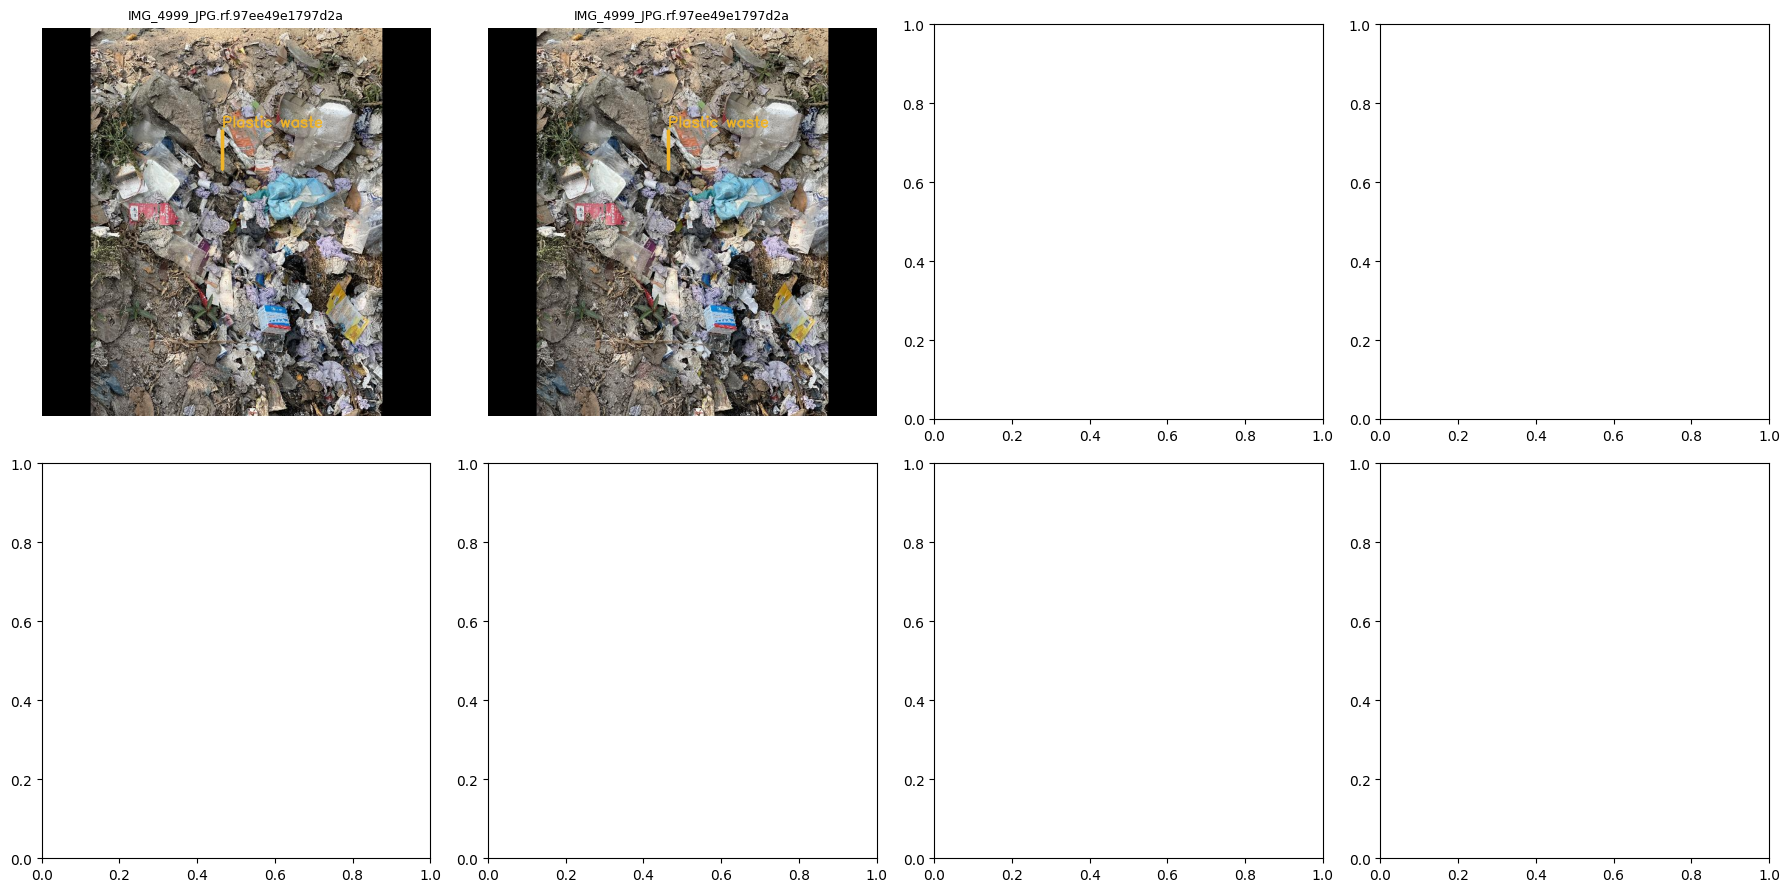

Saved annotation_samples.png to /content/drive/MyDrive/WasteWise_AI/reports
Do the boxes sit on the objects and do the names match? If not, do NOT train yet.


In [10]:
import cv2
import matplotlib.pyplot as plt

BOX_COLORS = [(230, 60, 60), (60, 160, 230), (60, 200, 90), (240, 180, 40), (170, 90, 220), (90, 90, 90)]


def yolo_to_pixels(box, width, height):
    """Convert normalized (class, xc, yc, w, h) to pixel corners (x1, y1, x2, y2)."""
    class_id, xc, yc, w, h = box
    x1, y1 = int((xc - w / 2) * width), int((yc - h / 2) * height)
    x2, y2 = int((xc + w / 2) * width), int((yc + h / 2) * height)
    return class_id, x1, y1, x2, y2


def draw_ground_truth(image_path, boxes):
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"cannot open image {image_path}")
    height, width = image.shape[:2]
    for box in boxes:
        class_id, x1, y1, x2, y2 = yolo_to_pixels(box, width, height)
        color = BOX_COLORS[class_id % len(BOX_COLORS)][::-1]
        cv2.rectangle(image, (x1, y1), (x2, y2), color, 3)
        cv2.putText(image, CLASS_NAMES[class_id], (x1, max(20, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


candidates = [r for r in records if r["split"] == "train" and parsed_boxes.get(r["image"])]
random.Random(RANDOM_SEED).shuffle(candidates)
samples = candidates[:8]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for axis, record in zip(axes.flat, samples):
    try:
        axis.imshow(draw_ground_truth(record["image"], parsed_boxes[record["image"]]))
        axis.set_title(record["image"].name[:30], fontsize=9)
    except Exception as err:
        axis.text(0.5, 0.5, f"Could not draw:\n{err}", ha="center")
    axis.axis("off")
plt.tight_layout()
fig.savefig(REPORTS_DIR / "annotation_samples.png", dpi=100)
plt.show()
print("Saved annotation_samples.png to", REPORTS_DIR)
print("Do the boxes sit on the objects and do the names match? If not, do NOT train yet.")

## Section 9 — Configure and train the model

**What it does:** sets random seeds, loads the pretrained model named in `MODEL_NAME`, and fine-tunes it on your dataset. The validation split picks the best checkpoint; the test split is **not** used here.

**Important**
- Results go straight to Google Drive (`training_outputs`), so a runtime reset will not lose them.
- If a finished run already exists, training is skipped (set `FORCE_RETRAIN = True` to train again).
- Typical GPU time is tens of minutes; on CPU it can take many hours.
- Starting values (50 epochs, size 640, batch 16, patience 10) are *starting points*, not tuned settings.

**If it fails:** *out of memory* → lower `BATCH_SIZE` (or `IMAGE_SIZE`) in Section 2 and re-run from Section 2's cell then this cell. *Model download error* → check internet / update `ultralytics` (`pip install -U ultralytics`).

In [11]:
from ultralytics import YOLO

LAST_RUN_FILE = OUTPUT_DIR / "last_run.txt"


def find_run_dir():
    """Locate the run folder that contains weights/best.pt (never assume the name)."""
    if LAST_RUN_FILE.exists():
        remembered = Path(LAST_RUN_FILE.read_text().strip())
        if (remembered / "weights" / "best.pt").exists():
            return remembered
    runs = [d for d in OUTPUT_DIR.glob(f"{RUN_NAME}*") if (d / "weights" / "best.pt").exists()]
    return max(runs, key=lambda d: d.stat().st_mtime) if runs else None


random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

try:
    from ultralytics import settings
    settings.update({"wandb": False, "comet": False})   # no external logging services
except Exception:
    pass

if not CLASS_NAMES_VERIFIED and not CLASS_NAMES_CONFIRMED:
    raise RuntimeError("Class names are unverified. Check Section 8, then set CLASS_NAMES_CONFIRMED = True in Section 2.")

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Training device:", DEVICE if DEVICE == "cpu" else torch.cuda.get_device_name(0))

RUN_DIR = find_run_dir()
if RUN_DIR is not None and not FORCE_RETRAIN:
    print(f"A finished run already exists, skipping training: {RUN_DIR}")
else:
    model = YOLO(MODEL_NAME)
    try:
        model.train(
            data=str(DATA_YAML),
            epochs=EPOCHS,
            imgsz=IMAGE_SIZE,
            batch=BATCH_SIZE,
            patience=PATIENCE,
            seed=RANDOM_SEED,
            device=DEVICE,
            project=str(OUTPUT_DIR),
            name=RUN_NAME,
            exist_ok=False,         # a new numbered folder is made if the name exists
            plots=True,
            workers=2,
        )
    except torch.cuda.OutOfMemoryError:
        raise RuntimeError("GPU ran out of memory. Lower BATCH_SIZE (e.g. 8 or 4) in Section 2 and run again.")
    RUN_DIR = Path(model.trainer.save_dir)
    LAST_RUN_FILE.write_text(str(RUN_DIR))

# Do not claim success unless the expected files really exist.
for expected in [RUN_DIR / "weights" / "best.pt", RUN_DIR / "weights" / "last.pt", RUN_DIR / "results.csv"]:
    if not expected.exists():
        raise RuntimeError(f"Training did not produce {expected}. Read the training log above for the error.")
print("\nTraining output folder:", RUN_DIR)
print("Best checkpoint       :", RUN_DIR / "weights" / "best.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Training device: Tesla T4
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/WasteWise_AI/configs/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=

## Section 10 — Inspect training results

**What it does:** reads `results.csv` and the plots Ultralytics generated, and shows them.

**How to read them (beginner version)**
- **Loss curves** (box / class / dfl): lower is better. *Training* loss should fall steadily.
- **Validation loss**: if it stops falling or rises while training loss keeps falling, the model is starting to *overfit* (memorizing training images).
- **Precision**: of the boxes the model drew, how many were right. **Recall**: of the real objects, how many it found.
- **mAP50 / mAP50-95**: overall detection quality (higher is better; 50-95 is stricter about box position).
- **Confusion matrix**: rows/columns are classes; large off-diagonal numbers are classes being mixed up, and the "background" row/column shows missed objects and false alarms.

Last epochs:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
36,37,2634.41,0.62470,0.76494,1.02694,0.68776,0.55619,0.62646,0.49760,0.72259,0.99978,1.11535,0.000359,0.000359,0.000359
37,38,2706.64,0.61881,0.75147,1.02247,0.73577,0.53509,0.64320,0.51016,0.72300,1.00572,1.11748,0.000334,0.000334,0.000334
38,39,2777.41,0.61097,0.76055,1.01607,0.66011,0.56995,0.63758,0.50879,0.70938,0.99718,1.11318,0.000309,0.000309,0.000309
39,40,2848.29,0.60903,0.74402,1.01779,0.68775,0.56250,0.62913,0.50282,0.72195,1.01712,1.12051,0.000285,0.000285,0.000285
40,41,2911.21,0.57980,0.67836,0.99847,0.71051,0.55549,0.63322,0.50104,0.74194,0.99315,1.13924,0.000260,0.000260,0.000260


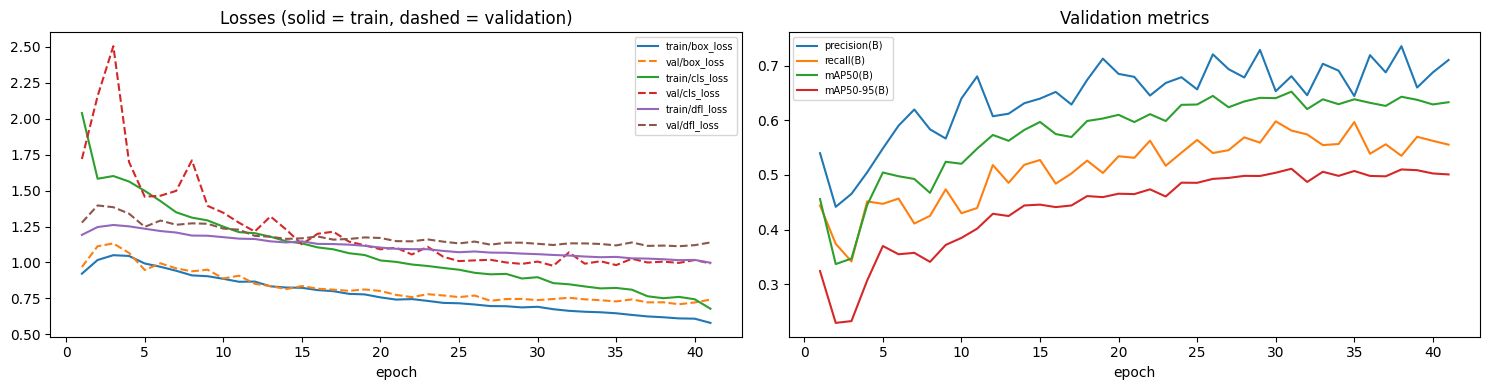

Best validation mAP50-95 0.511 at epoch 31 (of 41 epochs run).
Hint: validation box loss rose while training loss fell over the last 5 epochs - possible overfitting.

 results.png


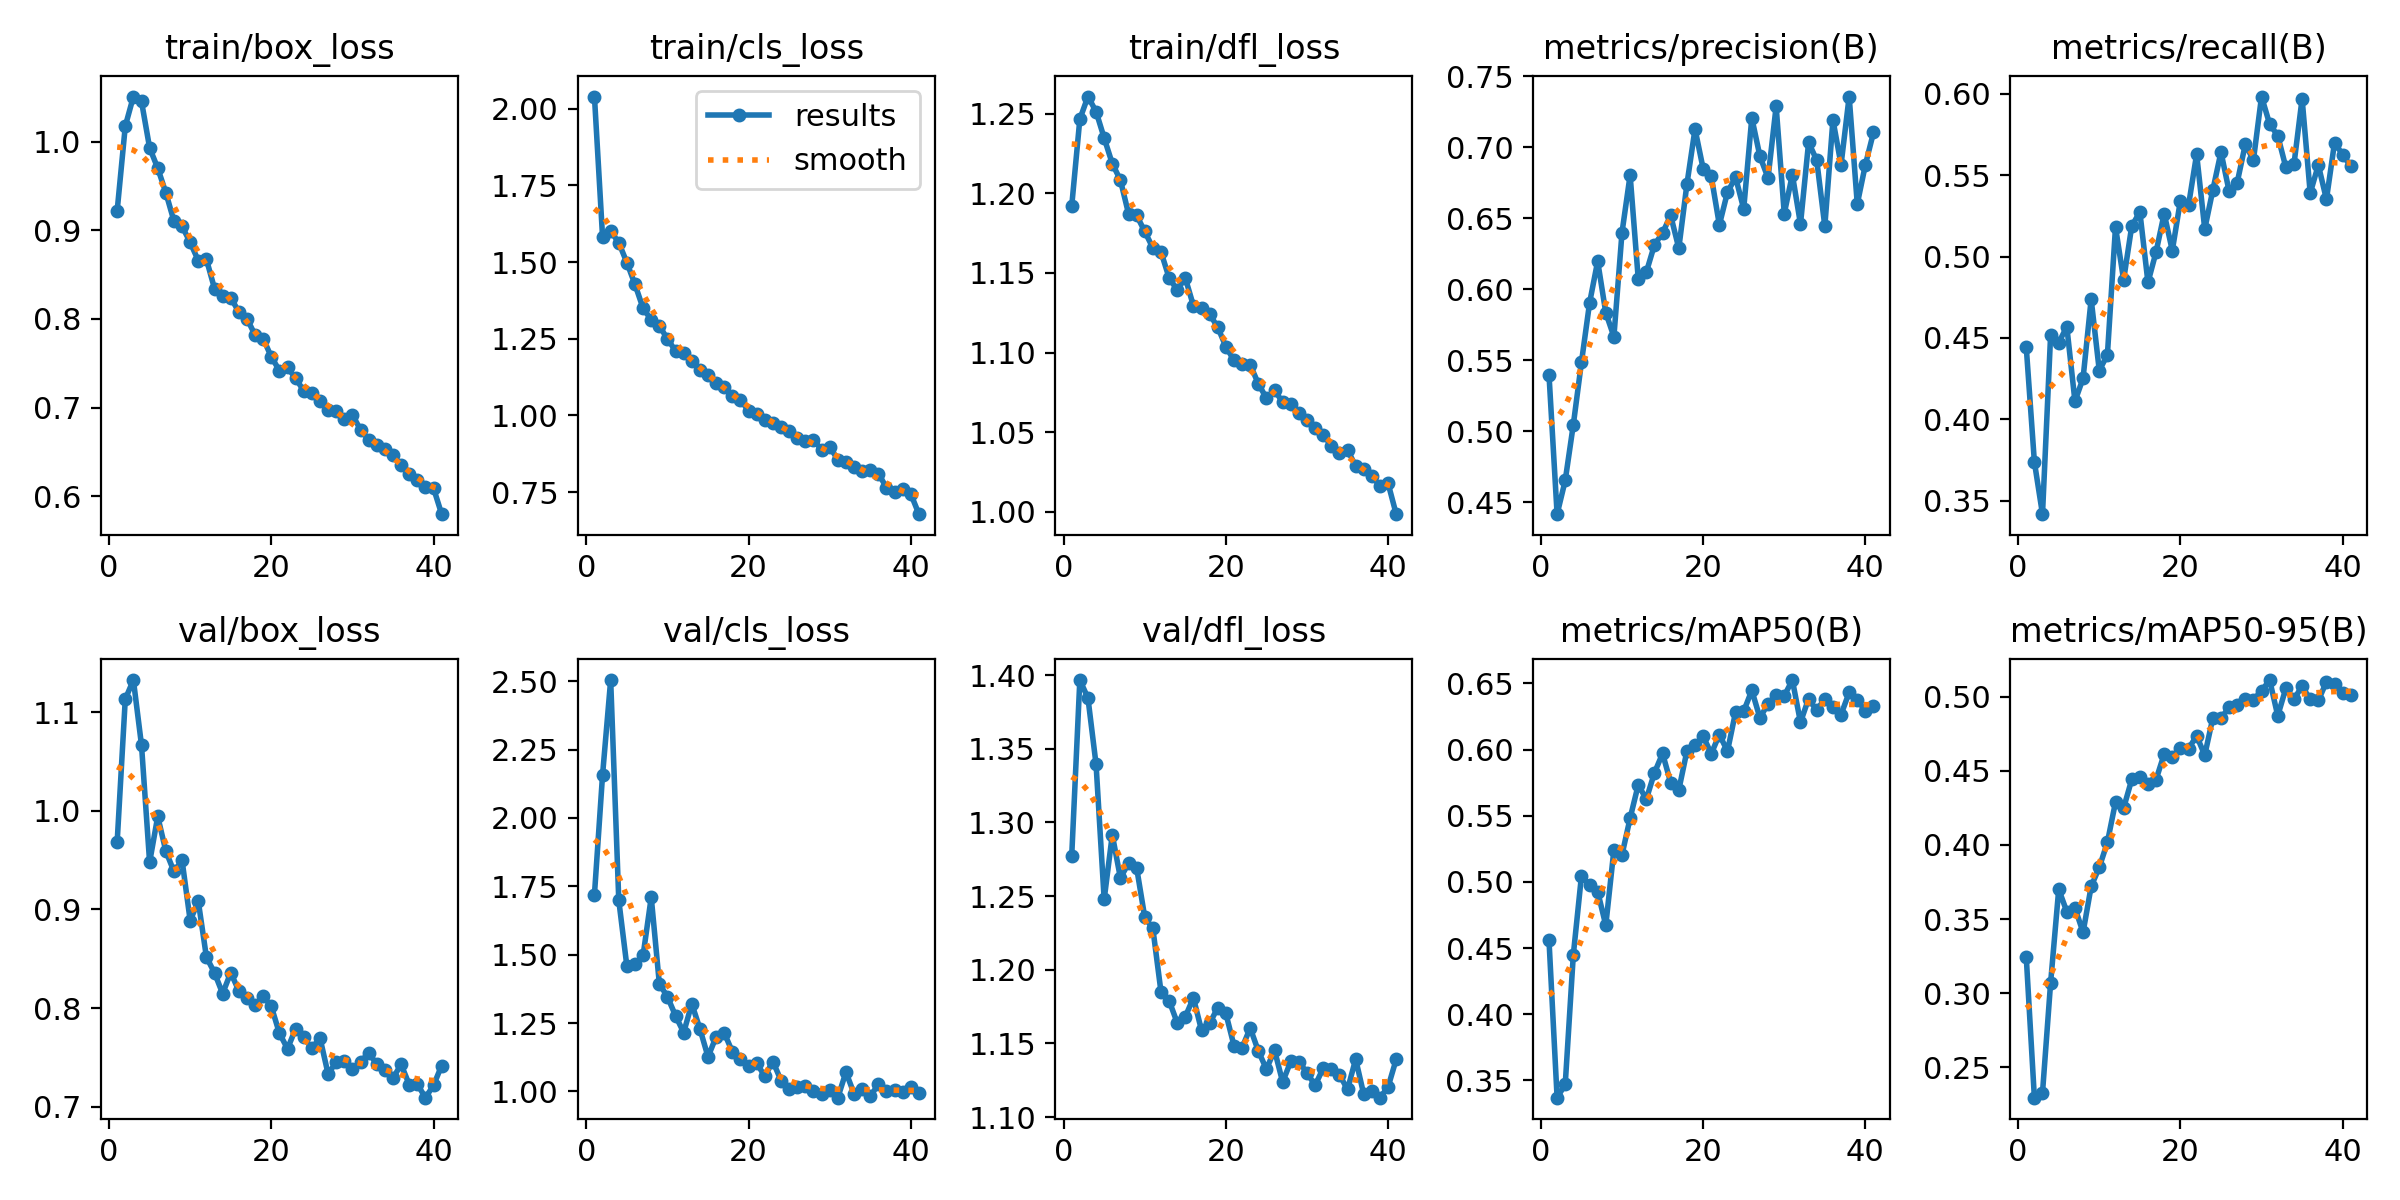


 confusion_matrix_normalized.png


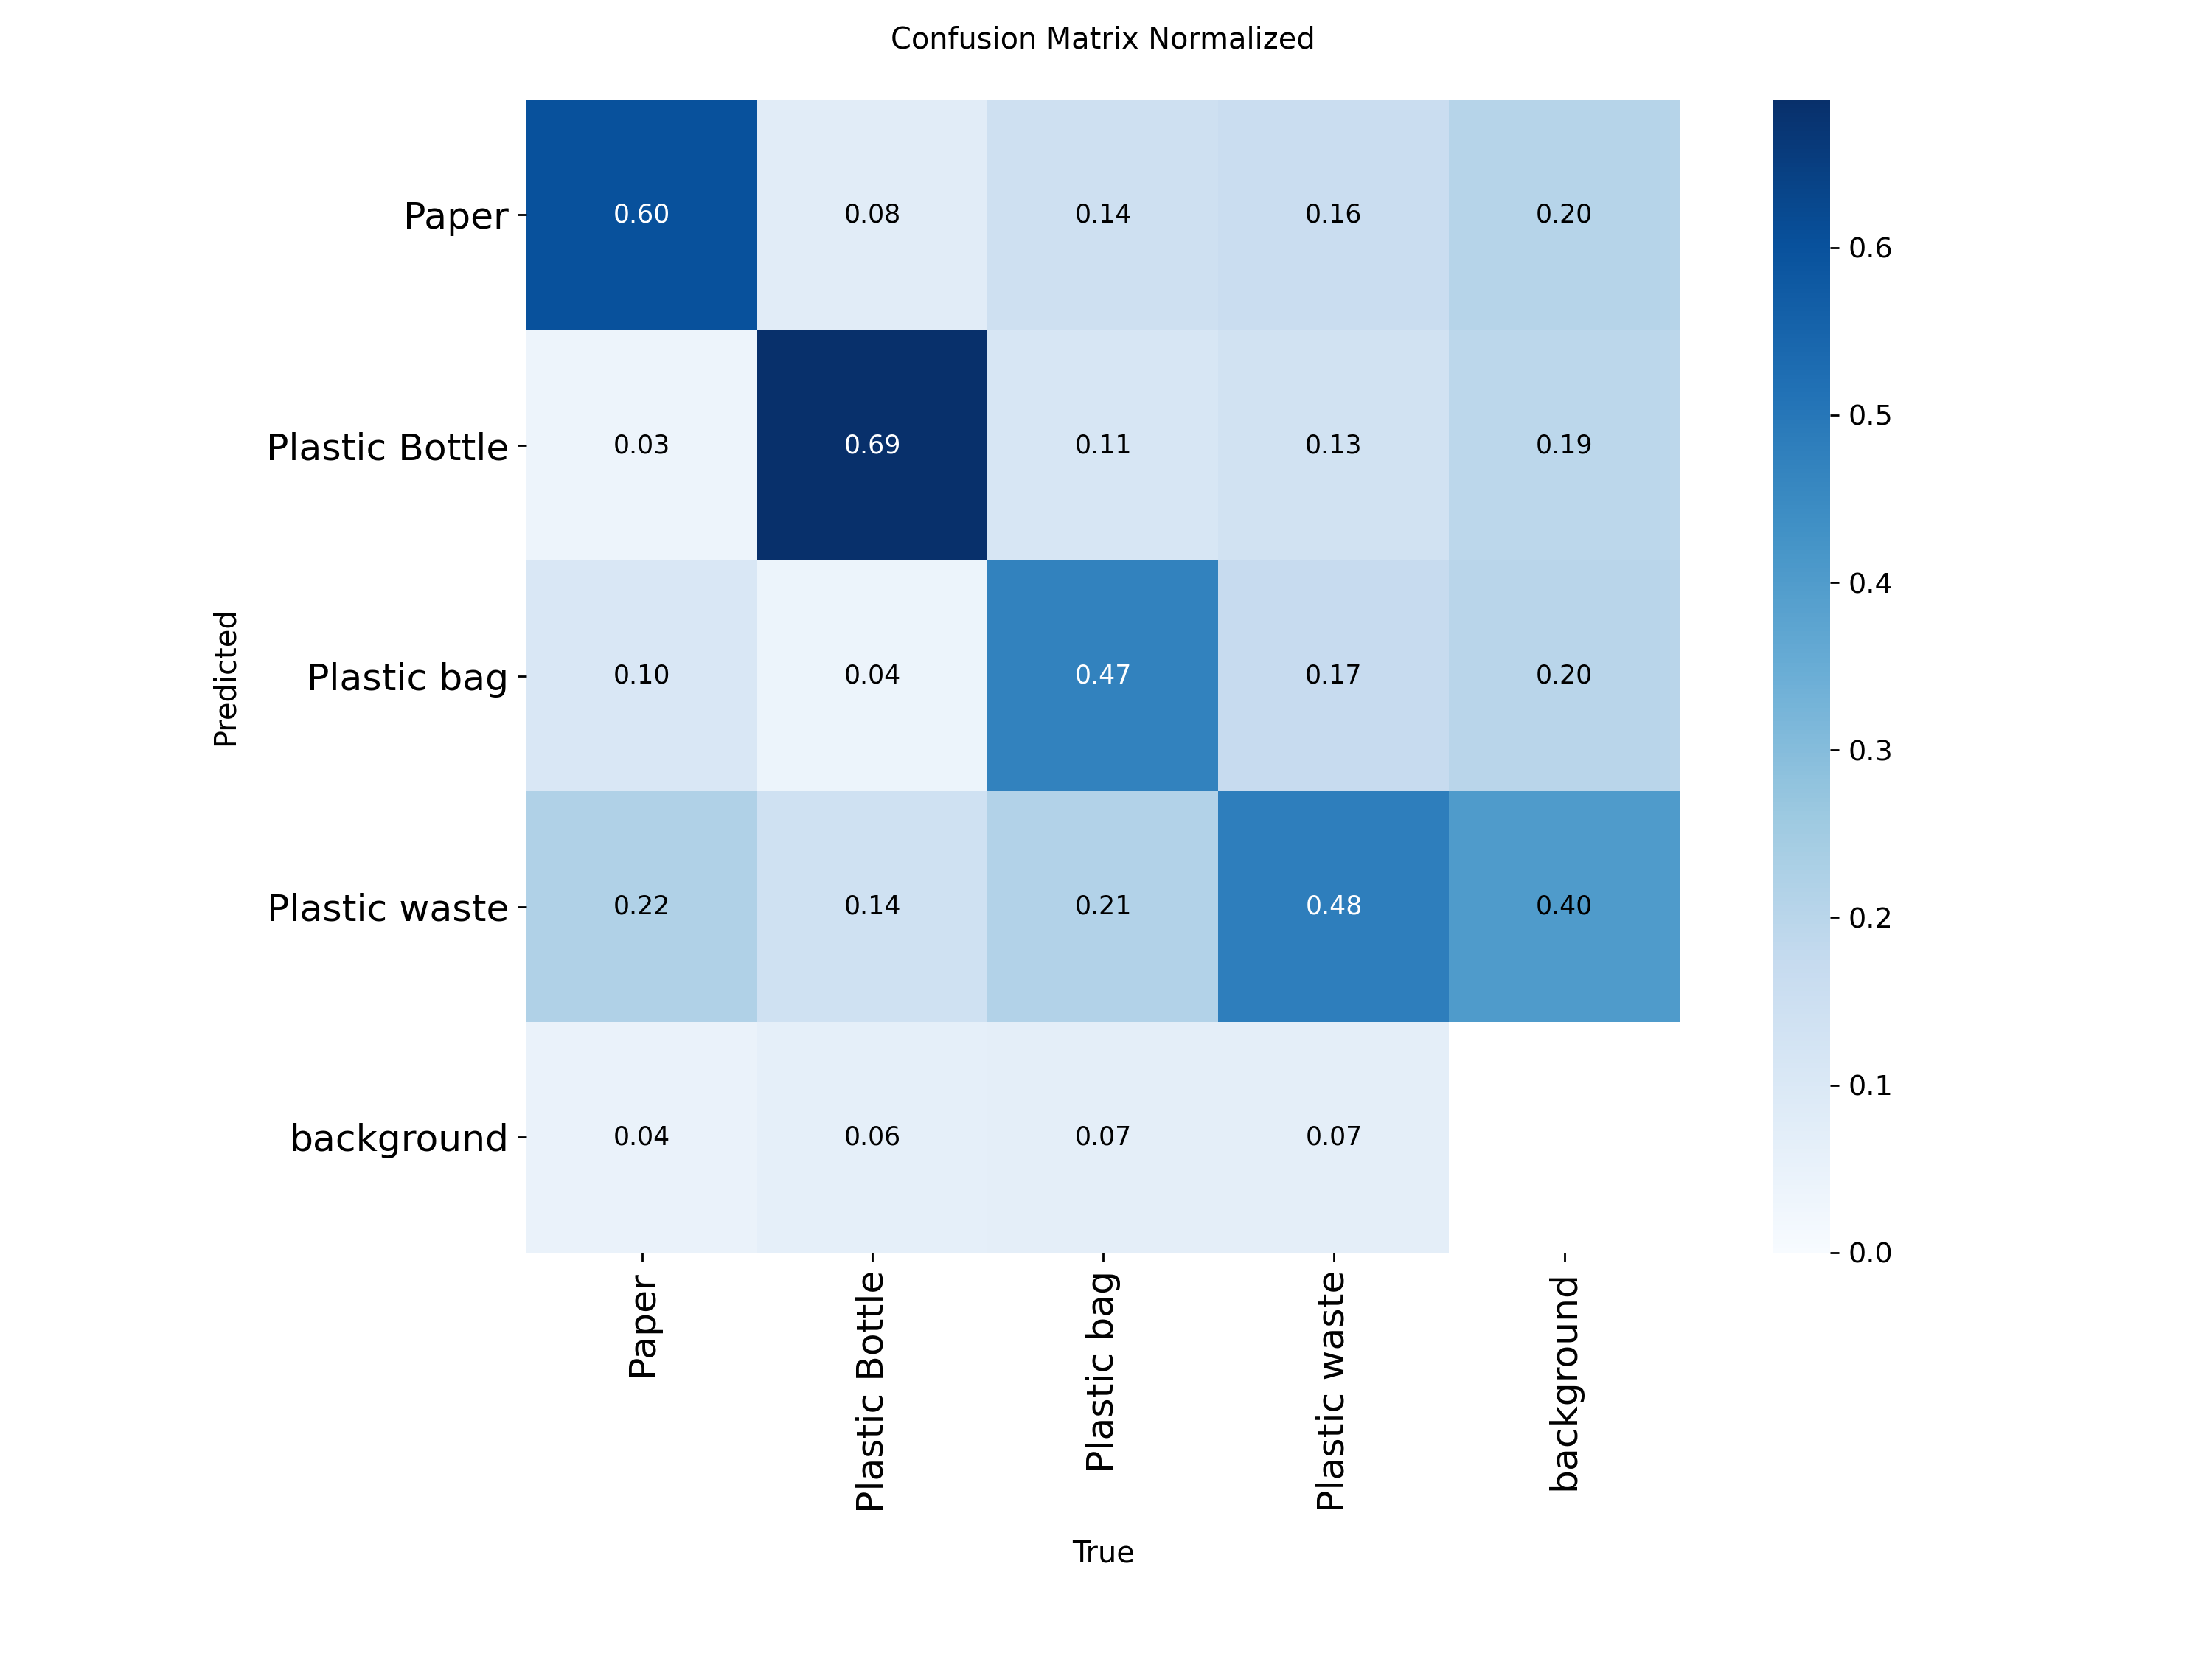


 BoxPR_curve.png


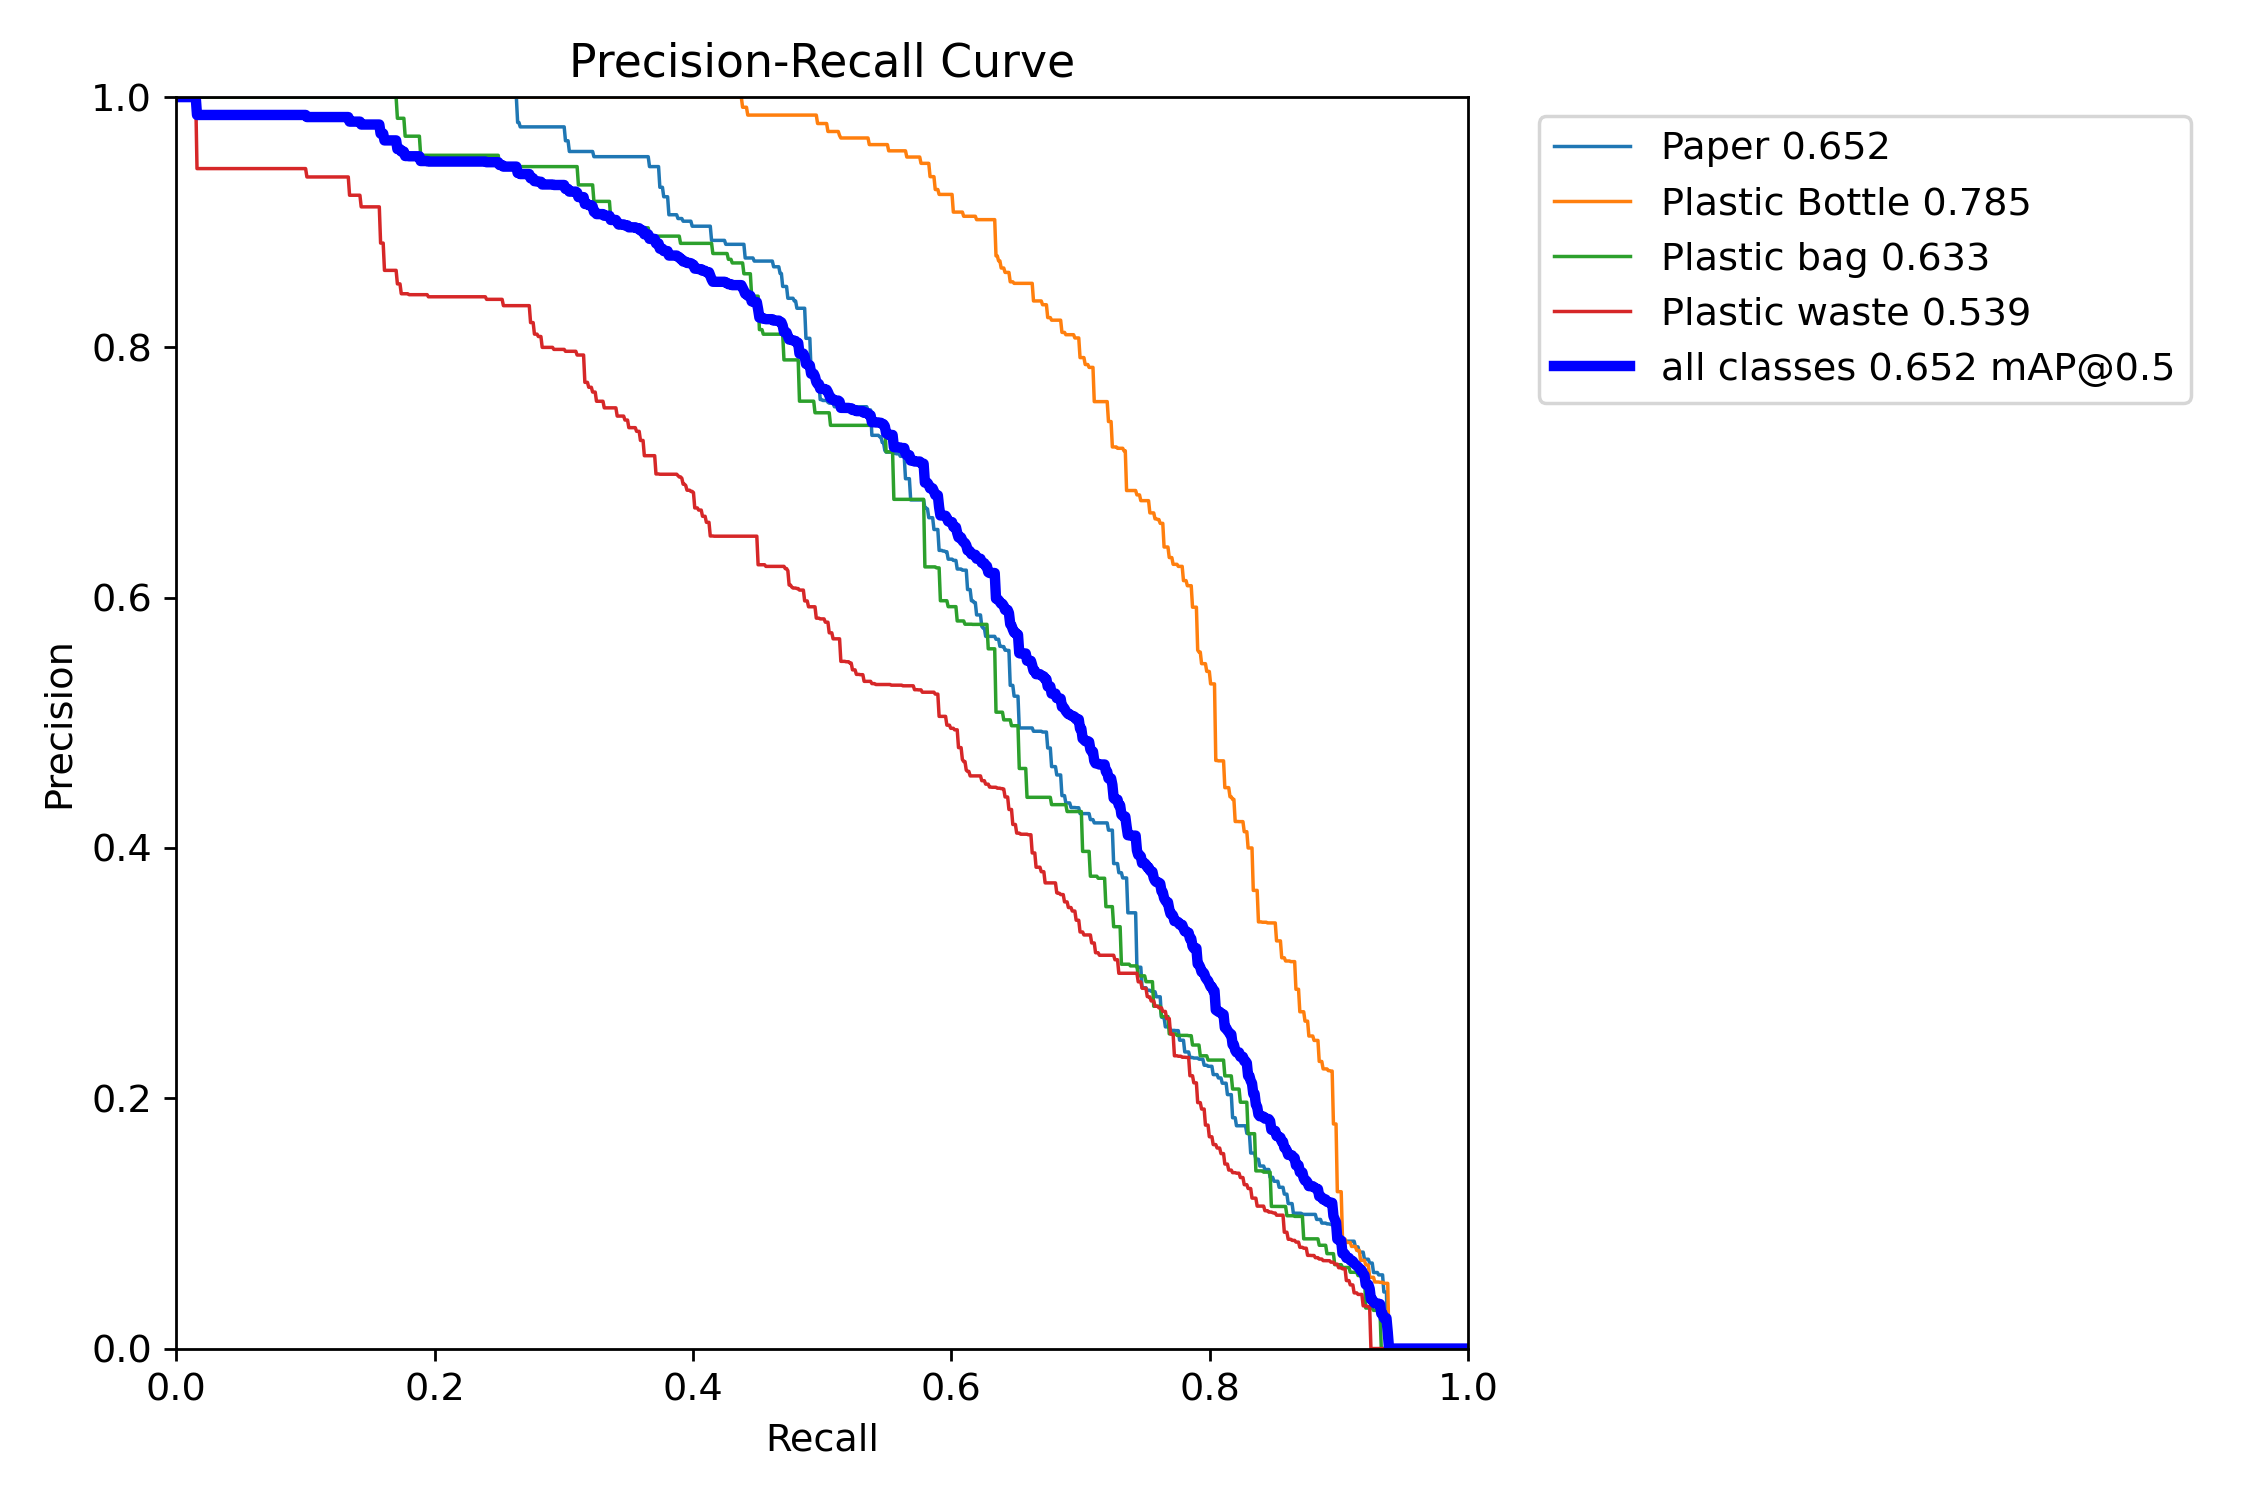


 val_batch0_pred.jpg


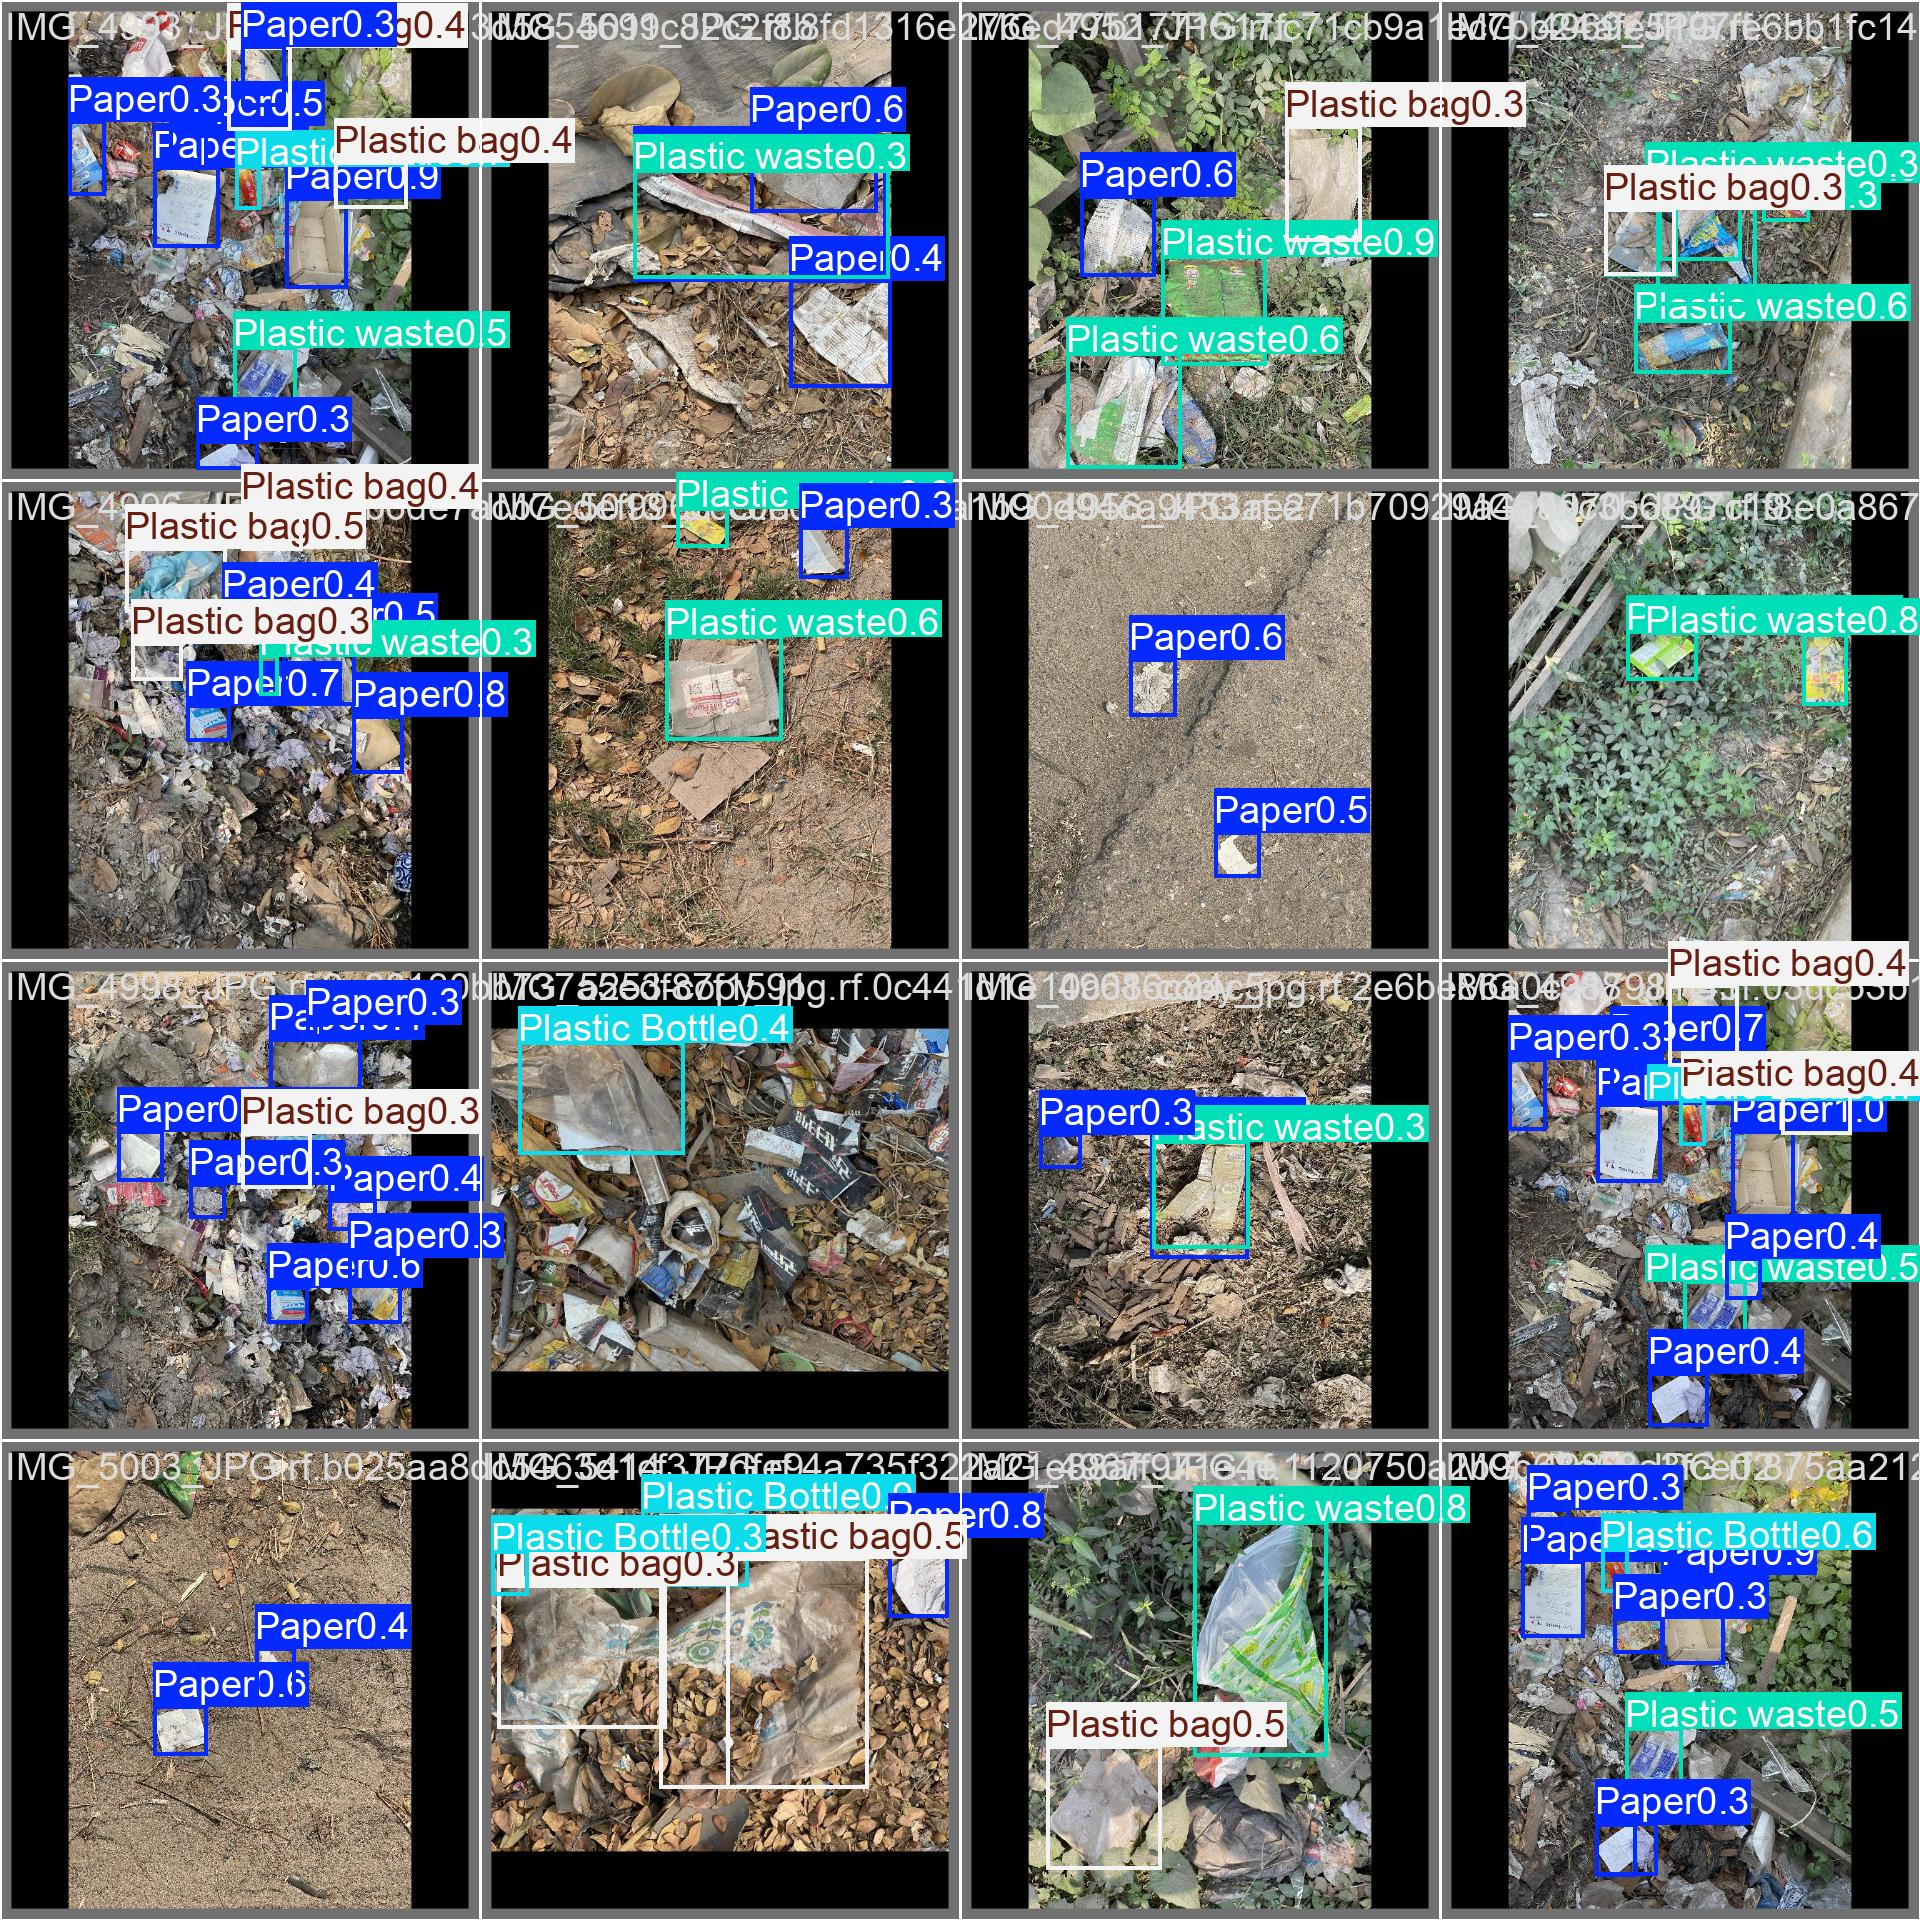

In [12]:
from IPython.display import display, Image as IPImage

results_df = pd.read_csv(RUN_DIR / "results.csv")
results_df.columns = [c.strip() for c in results_df.columns]
print("Last epochs:")
display(results_df.tail(5))

loss_pairs = [("train/box_loss", "val/box_loss"), ("train/cls_loss", "val/cls_loss"), ("train/dfl_loss", "val/dfl_loss")]
metric_cols = ["metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for train_col, val_col in loss_pairs:
    if train_col in results_df and val_col in results_df:
        axes[0].plot(results_df["epoch"], results_df[train_col], label=train_col)
        axes[0].plot(results_df["epoch"], results_df[val_col], "--", label=val_col)
axes[0].set_title("Losses (solid = train, dashed = validation)")
axes[0].set_xlabel("epoch")
axes[0].legend(fontsize=7)
for col in metric_cols:
    if col in results_df:
        axes[1].plot(results_df["epoch"], results_df[col], label=col.replace("metrics/", ""))
axes[1].set_title("Validation metrics")
axes[1].set_xlabel("epoch")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

if "metrics/mAP50-95(B)" in results_df:
    best_row = results_df.loc[results_df["metrics/mAP50-95(B)"].idxmax()]
    print(f"Best validation mAP50-95 {best_row['metrics/mAP50-95(B)']:.3f} at epoch {int(best_row['epoch'])} "
          f"(of {len(results_df)} epochs run).")

# Simple overfitting hint: validation box loss rising over the last few epochs while training loss falls.
if {"train/box_loss", "val/box_loss"} <= set(results_df.columns) and len(results_df) >= 8:
    recent = results_df.tail(5)
    if recent["val/box_loss"].iloc[-1] > recent["val/box_loss"].iloc[0] and recent["train/box_loss"].iloc[-1] < recent["train/box_loss"].iloc[0]:
        print("Hint: validation box loss rose while training loss fell over the last 5 epochs - possible overfitting.")
    else:
        print("No clear overfitting sign in the last 5 epochs' box loss.")

for plot_name in ["results.png", "confusion_matrix_normalized.png", "BoxPR_curve.png", "val_batch0_pred.jpg"]:
    plot_path = RUN_DIR / plot_name
    if plot_path.exists():
        print("\n", plot_name)
        display(IPImage(filename=str(plot_path), width=800))
    else:
        print(f"\n({plot_name} was not generated by this ultralytics version - skipped)")

## Section 11 — Final evaluation on the held-out test set

**What it does**
1. Loads `best.pt` and computes metrics on the **validation** split and on the **test** split (the test set is used *only here*).
2. Reports mAP50, mAP50-95, precision and recall — overall and per class — plus the speed numbers Ultralytics measured.
3. Does a simple error analysis at your confidence threshold: counts correct detections, false positives and missed objects (a prediction is "correct" if the class matches and IoU ≥ 0.5) and shows examples.
4. Saves `evaluation.json`, `evaluation.csv` and `evaluation.md` to Drive.

**Reading the results:** *validation* numbers were used to pick the checkpoint, so they can be a little optimistic. *Test* numbers are the honest estimate. Neither guarantees performance on photos unlike the dataset.

**If it fails:** if there is no test split, this section reports validation only and says so.

In [14]:
import gc
import torch

# Release unused GPU memory
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Reload the trained model to start prediction cleanly
best_model = YOLO(str(BEST_PT))

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1146.5±549.7 MB/s, size: 52.8 KB)
val: Scanning /content/wastewise_dataset/bangladesh_recyclable_waste_dataset/data_canonical_75-15-10/valid/labels.cache... 852 images, 0 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 852/852 274.9Mit/s 0.0s
val: /content/wastewise_dataset/bangladesh_recyclable_waste_dataset/data_canonical_75-15-10/valid/images/IMG_4925_JPG.rf.dd3ae7eccf7a67b5a6a56084f828da09.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/wastewise_dataset/bangladesh_recyclable_waste_dataset/data_canonical_75-15-10/valid/images/IMG_4975_JPG.rf.674b8a5fb777fa93eb9fb78391269670.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/wastewise_dataset/bangladesh_recyclable_waste_dataset/data_robustness_70-15-15

,class_id,class_name,precision,recall,mAP50,mAP50-95
0,0,Paper,0.720,0.549,0.652,0.541
1,1,Plastic Bottle,0.785,0.707,0.786,0.653
2,2,Plastic bag,0.609,0.591,0.632,0.482
3,3,Plastic waste,0.622,0.471,0.539,0.374


Speed (ms/image): {'preprocess': 1.7, 'inference': 4.4, 'loss': 0.0, 'postprocess': 1.5}

=== TEST ===  precision 0.758 | recall 0.648 | mAP50 0.724 | mAP50-95 0.588


,class_id,class_name,precision,recall,mAP50,mAP50-95
0,0,Paper,0.800,0.686,0.789,0.680
1,1,Plastic Bottle,0.902,0.778,0.861,0.727
2,2,Plastic bag,0.762,0.696,0.762,0.579
3,3,Plastic waste,0.566,0.432,0.486,0.364


Speed (ms/image): {'preprocess': 1.5, 'inference': 4.5, 'loss': 0.0, 'postprocess': 1.6}

Error analysis: {'split': 'test', 'confidence_threshold': 0.25, 'iou_for_match': 0.5, 'correct_detections': 4, 'false_positives': 2950, 'missed_objects': 4, 'precision_at_threshold': 0.001, 'recall_at_threshold': 0.5}


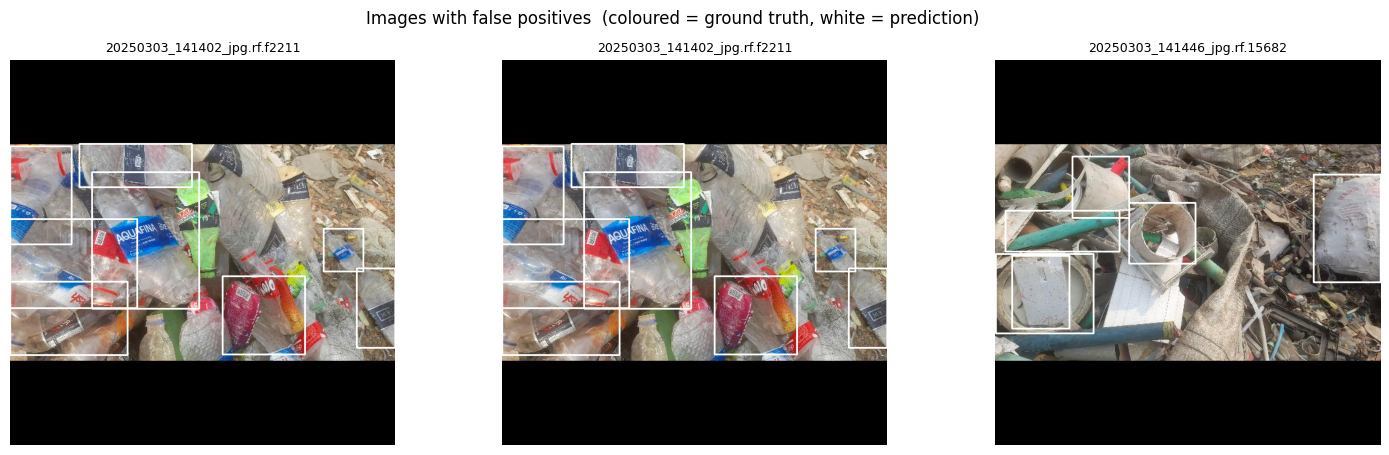

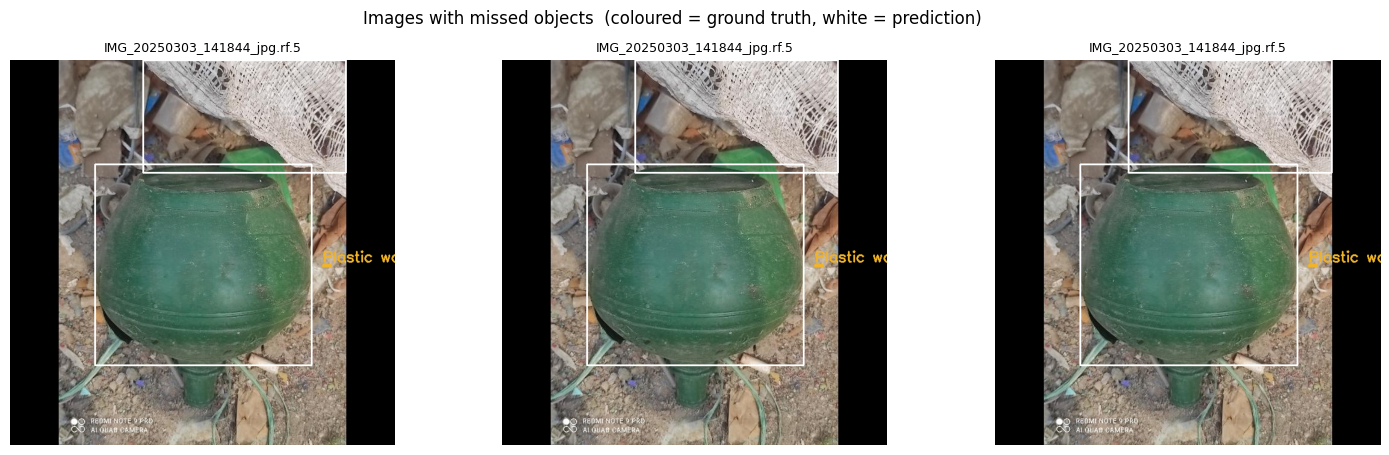


Saved evaluation.json, evaluation.csv and evaluation.md to /content/drive/MyDrive/WasteWise_AI/reports


In [15]:
BEST_PT = RUN_DIR / "weights" / "best.pt"
best_model = YOLO(str(BEST_PT))


def evaluate_split(split):
    """Run Ultralytics validation on one split and return a plain dict of the numbers."""
    m = best_model.val(data=str(DATA_YAML), split=split, imgsz=IMAGE_SIZE, batch=BATCH_SIZE, device=DEVICE,
                       project=str(OUTPUT_DIR), name=f"{RUN_DIR.name}_{split}_eval", exist_ok=True,
                       plots=True, verbose=False)
    per_class = []
    for position, class_id in enumerate(m.box.ap_class_index):
        per_class.append({
            "class_id": int(class_id),
            "class_name": CLASS_NAMES[int(class_id)],
            "precision": float(m.box.p[position]),
            "recall": float(m.box.r[position]),
            "mAP50": float(m.box.ap50[position]),
            "mAP50-95": float(m.box.ap[position]),
        })
    return {
        "split": split,
        "precision": float(m.box.mp),
        "recall": float(m.box.mr),
        "mAP50": float(m.box.map50),
        "mAP50-95": float(m.box.map),
        "per_class": per_class,
        "speed_ms_per_image": {k: float(v) for k, v in m.speed.items()},
    }


evaluation = {
    "environment": {
        "device": torch.cuda.get_device_name(0) if HAS_GPU else "cpu",
        "versions": PACKAGE_VERSIONS,
        "speed_method": "Per-image averages (ms) reported by the Ultralytics validator over the whole split, "
                        "on this Colab machine at the configured batch size. Not representative of a local CPU.",
    },
    "validation": evaluate_split("val"),
}
has_test_split = "test" in yaml_dict
if has_test_split:
    evaluation["test"] = evaluate_split("test")
else:
    print("No test split available - only validation metrics are reported.")

for key in ["validation", "test"]:
    if key in evaluation:
        e = evaluation[key]
        print(f"\n=== {key.upper()} ===  precision {e['precision']:.3f} | recall {e['recall']:.3f} | "
              f"mAP50 {e['mAP50']:.3f} | mAP50-95 {e['mAP50-95']:.3f}")
        display(pd.DataFrame(e["per_class"]).round(3))
        print("Speed (ms/image):", {k: round(v, 1) for k, v in e["speed_ms_per_image"].items()})

# ---------- Error analysis on the test split (or validation if no test split) ----------
analysis_split = "test" if has_test_split else "val"
analysis_records = [r for r in records if r["split"] == analysis_split]


def box_iou(a, b):
    """IoU of two boxes given as (x1, y1, x2, y2)."""
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def to_corners(box):
    class_id, xc, yc, w, h = box
    return class_id, (xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2)


total_tp = total_fp = total_fn = 0
false_positive_examples, missed_examples = [], []
for record in analysis_records:
    # Predict one image at a time to reduce GPU memory usage
    result = best_model.predict(
        source=str(record["image"]),
        conf=CONFIDENCE_THRESHOLD,
        iou=IOU_THRESHOLD,
        imgsz=IMAGE_SIZE,
        device=DEVICE,
        batch=1,
        stream=False,
        verbose=False
    )[0]

    truths = [
        to_corners(b)
        for b in parsed_boxes.get(record["image"], [])
    ]

    order = sorted(
        range(len(result.boxes)),
        key=lambda i: -float(result.boxes.conf[i])
    )

    predictions = [
        (
            int(result.boxes.cls[i]),
            tuple(result.boxes.xyxyn[i].tolist())
        )
        for i in order
    ]

    matched = set()
    tp = 0

    for pred_class, pred_box in predictions:
        best_index, best_iou = None, 0.5

        for index, (true_class, true_box) in enumerate(truths):
            if index in matched or true_class != pred_class:
                continue

            iou = box_iou(pred_box, true_box)

            if iou >= best_iou:
                best_index, best_iou = index, iou

        if best_index is not None:
            matched.add(best_index)
            tp += 1

    fp = len(predictions) - tp
    fn = len(truths) - tp

    total_tp += tp
    total_fp += fp
    total_fn += fn

    if fp and len(false_positive_examples) < 3:
        false_positive_examples.append((record["image"], result))

    if fn and len(missed_examples) < 3:
        missed_examples.append((record["image"], result))

    # Periodically release unused cached memory
    if (total_tp + total_fp + total_fn) > 0:
        if len(false_positive_examples) + len(missed_examples) >= 6:
            pass

    truths = [to_corners(b) for b in parsed_boxes.get(record["image"], [])]
    order = sorted(range(len(result.boxes)), key=lambda i: -float(result.boxes.conf[i]))
    predictions = [(int(result.boxes.cls[i]), tuple(result.boxes.xyxyn[i].tolist())) for i in order]
    matched = set()
    tp = 0
    for pred_class, pred_box in predictions:
        best_index, best_iou = None, 0.5
        for index, (true_class, true_box) in enumerate(truths):
            if index in matched or true_class != pred_class:
                continue
            iou = box_iou(pred_box, true_box)
            if iou >= best_iou:
                best_index, best_iou = index, iou
        if best_index is not None:
            matched.add(best_index)
            tp += 1
    fp, fn = len(predictions) - tp, len(truths) - tp
    total_tp, total_fp, total_fn = total_tp + tp, total_fp + fp, total_fn + fn
    if fp and len(false_positive_examples) < 3:
        false_positive_examples.append((record["image"], result))
    if fn and len(missed_examples) < 3:
        missed_examples.append((record["image"], result))

error_summary = {
    "split": analysis_split,
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "iou_for_match": 0.5,
    "correct_detections": total_tp,
    "false_positives": total_fp,
    "missed_objects": total_fn,
    "precision_at_threshold": total_tp / max(1, total_tp + total_fp),
    "recall_at_threshold": total_tp / max(1, total_tp + total_fn),
}
evaluation["error_analysis"] = error_summary
print("\nError analysis:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in error_summary.items()})


def show_examples(examples, title):
    if not examples:
        print(f"No examples of: {title}")
        return
    fig, axes = plt.subplots(1, len(examples), figsize=(6 * len(examples), 5))
    axes = np.atleast_1d(axes)
    for axis, (image_path, result) in zip(axes, examples):
        picture = draw_ground_truth(image_path, parsed_boxes.get(image_path, []))     # coloured = ground truth
        for box in result.boxes.xyxy.tolist():                                        # white dashed-looking = prediction
            cv2.rectangle(picture, (int(box[0]), int(box[1])), (int(box[2]), int(box[3])), (255, 255, 255), 2)
        axis.imshow(picture)
        axis.set_title(image_path.name[:28], fontsize=9)
        axis.axis("off")
    fig.suptitle(f"{title}  (coloured = ground truth, white = prediction)")
    plt.show()


show_examples(false_positive_examples, "Images with false positives")
show_examples(missed_examples, "Images with missed objects")

# ---------- Save reports ----------
(REPORTS_DIR / "evaluation.json").write_text(json.dumps(evaluation, indent=2))
csv_rows = []
for key in ["validation", "test"]:
    if key in evaluation:
        for row in evaluation[key]["per_class"]:
            csv_rows.append({"split": key, **row})
pd.DataFrame(csv_rows).to_csv(REPORTS_DIR / "evaluation.csv", index=False)

report_lines = ["# WasteWise AI - Evaluation report", "",
                f"Model: `{MODEL_NAME}` fine-tuned; checkpoint `{BEST_PT.name}` from run `{RUN_DIR.name}`.",
                f"Device used: {evaluation['environment']['device']}. Class names source: {CLASS_SOURCE}.", ""]
for key in ["validation", "test"]:
    if key in evaluation:
        e = evaluation[key]
        report_lines += [f"## {key.capitalize()} split", "",
                         f"precision {e['precision']:.3f} | recall {e['recall']:.3f} | mAP50 {e['mAP50']:.3f} | mAP50-95 {e['mAP50-95']:.3f}", "",
                         "| class | precision | recall | mAP50 | mAP50-95 |", "|---|---|---|---|---|"]
        report_lines += [f"| {r['class_name']} | {r['precision']:.3f} | {r['recall']:.3f} | {r['mAP50']:.3f} | {r['mAP50-95']:.3f} |" for r in e["per_class"]]
        report_lines.append("")
if not has_test_split:
    report_lines += ["**No test split was available; only validation metrics are reported.**", ""]
report_lines += ["## Error analysis", "", f"Split `{analysis_split}`, confidence >= {CONFIDENCE_THRESHOLD}, IoU >= 0.5: "
                 f"{total_tp} correct, {total_fp} false positives, {total_fn} missed objects.", "",
                 "## Notes", "", "- Validation numbers guided checkpoint choice; test numbers are the final estimate.",
                 "- Only four classes are supported; other objects may be missed or mislabelled.",
                 "- " + evaluation["environment"]["speed_method"]]
(REPORTS_DIR / "evaluation.md").write_text("\n".join(report_lines))
print("\nSaved evaluation.json, evaluation.csv and evaluation.md to", REPORTS_DIR)

## Section 12 — Predict on your own image

**What it does:** runs the best model on one image and shows the original next to the annotated result, lists every detection (class, confidence, box in pixels) and counts per class.

**How to use:** set `CUSTOM_IMAGE_PATH` to a file in Drive, or leave it `None` to upload a photo in Colab.

**Remember:** objects outside the four trained classes can be missed or mislabelled, and confidence is not a guarantee of correctness. If nothing is detected the result says so.

Saving images (2).jpg to images (2).jpg


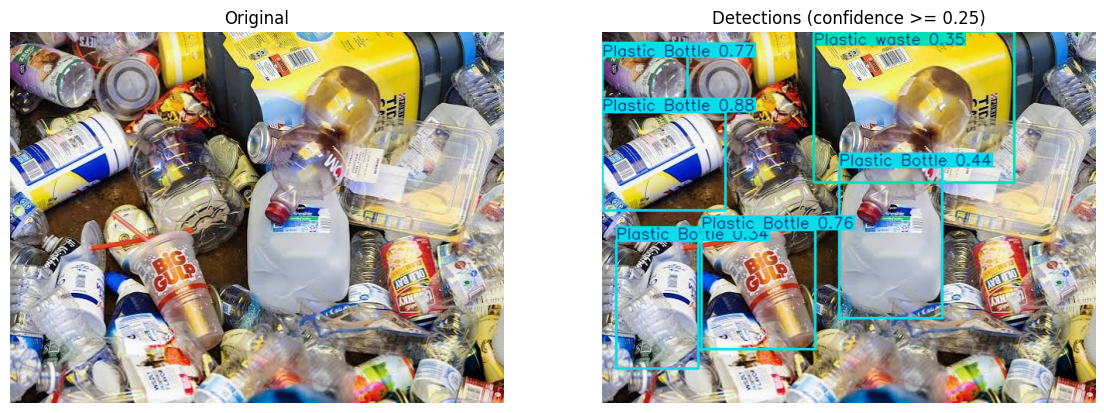

Plastic Bottle  confidence 0.88  box [x_min=0, y_min=105, x_max=160, y_max=232]
Plastic Bottle  confidence 0.77  box [x_min=0, y_min=15, x_max=111, y_max=100]
Plastic Bottle  confidence 0.76  box [x_min=129, y_min=257, x_max=276, y_max=410]
Plastic Bottle  confidence 0.44  box [x_min=306, y_min=175, x_max=440, y_max=371]
Plastic waste   confidence 0.35  box [x_min=273, y_min=0, x_max=533, y_max=195]
Plastic Bottle  confidence 0.34  box [x_min=18, y_min=270, x_max=125, y_max=435]

Counts by class: {'Paper': 0, 'Plastic Bottle': 5, 'Plastic bag': 0, 'Plastic waste': 1}
Saved annotated image to /content/drive/MyDrive/WasteWise_AI/predictions/custom_images (2)_annotated.jpg


In [22]:
CUSTOM_IMAGE_PATH = None                      # e.g. "/content/drive/MyDrive/my_photo.jpg"
PREDICT_CONFIDENCE = CONFIDENCE_THRESHOLD     # change here to be more / less strict

if CUSTOM_IMAGE_PATH is None:
    if IN_COLAB:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError("No file uploaded. Upload an image or set CUSTOM_IMAGE_PATH.")
        CUSTOM_IMAGE_PATH = "/content/" + next(iter(uploaded))
        Path(CUSTOM_IMAGE_PATH).write_bytes(uploaded[next(iter(uploaded))])
    else:
        raise RuntimeError("Set CUSTOM_IMAGE_PATH to an image file.")

custom_result = best_model.predict(CUSTOM_IMAGE_PATH, conf=PREDICT_CONFIDENCE, iou=IOU_THRESHOLD, imgsz=IMAGE_SIZE,
                                   device=DEVICE, verbose=False)[0]

original = cv2.cvtColor(cv2.imread(CUSTOM_IMAGE_PATH), cv2.COLOR_BGR2RGB)
annotated = cv2.cvtColor(custom_result.plot(), cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(original); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(annotated); axes[1].set_title(f"Detections (confidence >= {PREDICT_CONFIDENCE})"); axes[1].axis("off")
plt.show()

counts_by_class = {name: 0 for name in CLASS_NAMES}
if len(custom_result.boxes) == 0:
    print("No supported waste objects detected. (Objects outside the four trained classes may be missed.)")
for box, conf, class_id in zip(custom_result.boxes.xyxy.tolist(), custom_result.boxes.conf.tolist(), custom_result.boxes.cls.tolist()):
    name = CLASS_NAMES[int(class_id)]
    counts_by_class[name] += 1
    x1, y1, x2, y2 = (round(v) for v in box)
    print(f"{name:15s} confidence {conf:.2f}  box [x_min={x1}, y_min={y1}, x_max={x2}, y_max={y2}]")
print("\nCounts by class:", counts_by_class)

annotated_path = PREDICTIONS_DIR / f"custom_{Path(CUSTOM_IMAGE_PATH).stem}_annotated.jpg"
cv2.imwrite(str(annotated_path), custom_result.plot())
print("Saved annotated image to", annotated_path)

## Section 13 — Export the model and save everything to Drive

**What it does**
- Confirms `best.pt` exists, then copies it to `final_model/best.pt` in Drive.
- Writes `model_metadata.json` (class names, model name, training settings, package versions, dataset citation/license info, evaluation numbers) and `sha256.txt`.
- **Reloads** the exported file and runs it on an image to prove it works.

**Download for local use:** in Drive open `WasteWise_AI/final_model/` and download `best.pt` and `model_metadata.json`. See the README for the CPU smoke test and the later FastAPI step.

**If it fails:** "best.pt missing" means training did not finish; re-run Section 9.

In [24]:
def sha256_of_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


source_best = RUN_DIR / "weights" / "best.pt"
if not source_best.exists():
    raise FileNotFoundError(f"{source_best} is missing - training did not finish.")

exported_model = FINAL_MODEL_DIR / "best.pt"
if exported_model.exists() and sha256_of_file(exported_model) == sha256_of_file(source_best):
    print("Exported model is already up to date - not copying again.")
else:
    shutil.copy2(source_best, exported_model)

train_args_file = RUN_DIR / "args.yaml"
train_args = yaml.safe_load(train_args_file.read_text()) if train_args_file.exists() else {}
zenodo_info_file = CONFIG_DIR / "zenodo_record.json"
dataset_info = json.loads(zenodo_info_file.read_text()) if zenodo_info_file.exists() else {"record_url": f"https://zenodo.org/records/{ZENODO_RECORD_ID}"}

model_metadata = {
    "project": "WasteWise AI",
    "base_model": MODEL_NAME,
    "class_names": {str(i): n for i, n in enumerate(CLASS_NAMES)},
    "class_names_source": CLASS_SOURCE,
    "image_size": IMAGE_SIZE,
    "default_confidence_threshold": CONFIDENCE_THRESHOLD,
    "default_iou_threshold": IOU_THRESHOLD,
    "training_settings": {k: train_args.get(k) for k in ["epochs", "batch", "imgsz", "patience", "seed", "device"]},
    "run_directory": str(RUN_DIR),
    "package_versions": PACKAGE_VERSIONS,
    "dataset": dataset_info,
    "used_fallback_split": USED_FALLBACK_SPLIT,
    "evaluation_summary": {k: {m: evaluation[k][m] for m in ("precision", "recall", "mAP50", "mAP50-95")}
                           for k in ("validation", "test") if k in evaluation},
    "limitations": "Detects only the four trained classes; advisory only; does not determine recyclability.",
    "sha256": sha256_of_file(exported_model),
}
(FINAL_MODEL_DIR / "model_metadata.json").write_text(json.dumps(model_metadata, indent=2))
(FINAL_MODEL_DIR / "sha256.txt").write_text(f"{model_metadata['sha256']}  best.pt\n")

# Reload test: load the exported file fresh and run inference on one real image.
reload_record = next(r for r in records if r["split"] == ("test" if has_test_split else "val"))
reloaded = YOLO(str(exported_model))
reload_result = reloaded.predict(str(reload_record["image"]), conf=CONFIDENCE_THRESHOLD, imgsz=IMAGE_SIZE, device=DEVICE, verbose=False)[0]
assert reloaded.names is not None and len(reload_result.boxes) >= 0
print(f"Reload test passed: exported model ran on {reload_record['image'].name} and found {len(reload_result.boxes)} object(s).")
cv2.imwrite(str(PREDICTIONS_DIR / "reload_test_sample.jpg"), reload_result.plot())

print("\nSaved to", FINAL_MODEL_DIR)
for item in sorted(FINAL_MODEL_DIR.iterdir()):
    print(f"  {item.name}  ({item.stat().st_size / 1e6:.1f} MB)")
print("SHA-256:", model_metadata["sha256"])

Exported model is already up to date - not copying again.
Reload test passed: exported model ran on 20250303_141402_jpg.rf.f2211e490f02f41032a5d13ea2592134.jpg and found 8 object(s).

Saved to /content/drive/MyDrive/WasteWise_AI/final_model
  best.pt  (5.5 MB)
  model_metadata.json  (0.0 MB)
  sha256.txt  (0.0 MB)
SHA-256: bdc90d57143eb08b42eda854fe3b429983de4ed24fab4966205bd5a506a2cc4a


## Section 14 — Final summary and troubleshooting

In [25]:
print("=" * 60)
print("WASTEWISE AI - RUN SUMMARY")
print("=" * 60)
print("Dataset folder     :", DATASET_DIR)
print("Images per split   :", {s: per_split[s]["images"] for s in split_names})
print("Class mapping      :", {i: n for i, n in enumerate(CLASS_NAMES)}, f"[{CLASS_SOURCE}]")
print("Model              :", MODEL_NAME, "(fine-tuned)")
print("Training output    :", RUN_DIR)
print("Best checkpoint    :", exported_model)
for key in ["validation", "test"]:
    if key in evaluation:
        e = evaluation[key]
        print(f"{key.capitalize():18s} : mAP50 {e['mAP50']:.3f} | mAP50-95 {e['mAP50-95']:.3f} | P {e['precision']:.3f} | R {e['recall']:.3f}")
if not has_test_split:
    print("Test metrics       : not available (no test split)")
print("Example prediction :", annotated_path)

warnings_found = []
if not CLASS_NAMES_VERIFIED:
    warnings_found.append("Class names were not verified from dataset files (manually confirmed in Section 8).")
if USED_FALLBACK_SPLIT:
    warnings_found.append("A fallback split was used because no valid predefined split existed.")
if cross_split_duplicates:
    warnings_found.append(f"{len(cross_split_duplicates)} group(s) of identical images cross splits.")
if audit["problem_counts"]:
    warnings_found.append(f"Audit problems: {audit['problem_counts']} (see dataset_audit_issues.csv).")
if not has_test_split:
    warnings_found.append("No test split - only validation metrics exist.")
print("\nWarnings / unresolved issues:")
for item in warnings_found or ["none"]:
    print(" -", item)

WASTEWISE AI - RUN SUMMARY
Dataset folder     : /content/wastewise_dataset
Images per split   : {'train': 4121, 'val': 852, 'test': 711}
Class mapping      : {0: 'Paper', 1: 'Plastic Bottle', 2: 'Plastic bag', 3: 'Plastic waste'} [dataset file: bangladesh_recyclable_waste_dataset/data_canonical_75-15-10/data.yaml]
Model              : yolo11n.pt (fine-tuned)
Training output    : /content/drive/MyDrive/WasteWise_AI/training_outputs/wastewise_yolo
Best checkpoint    : /content/drive/MyDrive/WasteWise_AI/final_model/best.pt
Validation         : mAP50 0.653 | mAP50-95 0.512 | P 0.684 | R 0.580
Test               : mAP50 0.724 | mAP50-95 0.588 | P 0.758 | R 0.648
Example prediction : /content/drive/MyDrive/WasteWise_AI/predictions/custom_images (2)_annotated.jpg

Warnings / unresolved issues:
 - 143 group(s) of identical images cross splits.
 - Audit problems: {'malformed_line': 12142, 'label_without_image': 10} (see dataset_audit_issues.csv).


### Troubleshooting

| Problem | What to do |
|---|---|
| **GPU unavailable** | Runtime → Change runtime type → choose a GPU. Free GPUs are not guaranteed; try later. CPU works but is very slow (lower `EPOCHS`). |
| **Out-of-memory error** | Lower `BATCH_SIZE` (8, 4) or `IMAGE_SIZE` (512) in Section 2, restart the runtime, re-run from the top (finished steps are skipped). |
| **Download or extraction failure** | Download the archive by hand from the Zenodo page, put it in `WasteWise_AI/downloads` on Drive, re-run Section 3. If extraction says "unsafe", do not use that archive. |
| **Wrong dataset paths** | Read the folder tree (Section 4) and the layout summary (Section 5). Split folders must be named like train / val(id) / test. |
| **Missing or corrupt labels** | Open `reports/dataset_audit_issues.csv`. Ultralytics skips corrupt labels and prints warnings; fix the source files rather than ignoring many problems. |
| **Class-ID mismatch (wrong names on boxes)** | Section 8 pictures show it. Check the dataset README for the real order, correct `EXPECTED_CLASS_NAMES`, and re-run Sections 2–8. |
| **`best.pt` missing** | Training stopped early or crashed. Read the training log; fix the cause; re-run Section 9. |
| **Drive mount problems** | Re-run the mount cell, approve access, or use *Runtime → Disconnect and delete runtime* and start again. |
| **Package/version conflicts** | Avoid downgrading torch. Try `pip install -U ultralytics`, restart the runtime, re-run. If `yolo11n.pt` is not recognised, update ultralytics or set `MODEL_NAME = "yolov8n.pt"`. |
| **Runtime reset after training** | Weights, reports and the YAML are on Drive. Re-run Sections 1–9 (the finished run is detected and training is skipped), then continue from Section 10. |

**Licenses:** check the dataset license (printed in Section 3) and the current Ultralytics license terms before redistributing or using the model commercially. This notebook gives no legal guarantee.

In [26]:
from google.colab import drive, files
from pathlib import Path
import shutil

drive.mount('/content/drive')

project = Path('/content/drive/MyDrive/WasteWise_AI')
bundle = Path('/content/wastewise_model_bundle')

# Create a clean folder
if bundle.exists():
    shutil.rmtree(bundle)

bundle.mkdir(parents=True)

# Required model file
model_file = project / 'final_model' / 'best.pt'

if not model_file.exists():
    raise FileNotFoundError(f'Model not found: {model_file}')

shutil.copy2(model_file, bundle / 'best.pt')

# Copy metadata if available
metadata_file = project / 'final_model' / 'model_metadata.json'

if metadata_file.exists():
    shutil.copy2(metadata_file, bundle / 'model_metadata.json')
else:
    print('Warning: model_metadata.json was not found.')

# Create ZIP
zip_path = shutil.make_archive(
    '/content/WasteWise_Model_Bundle',
    'zip',
    root_dir=bundle
)

print('Files included:')
for file in bundle.iterdir():
    print('-', file.name)

files.download(zip_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files included:
- model_metadata.json
- best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
from pathlib import Path
from google.colab import files
import shutil

reports_dir = Path(
    '/content/drive/MyDrive/WasteWise_AI/reports'
)

if reports_dir.exists():
    zip_path = shutil.make_archive(
        '/content/WasteWise_Reports',
        'zip',
        root_dir=reports_dir
    )
    files.download(zip_path)
else:
    print('Reports folder not found at:', reports_dir)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>